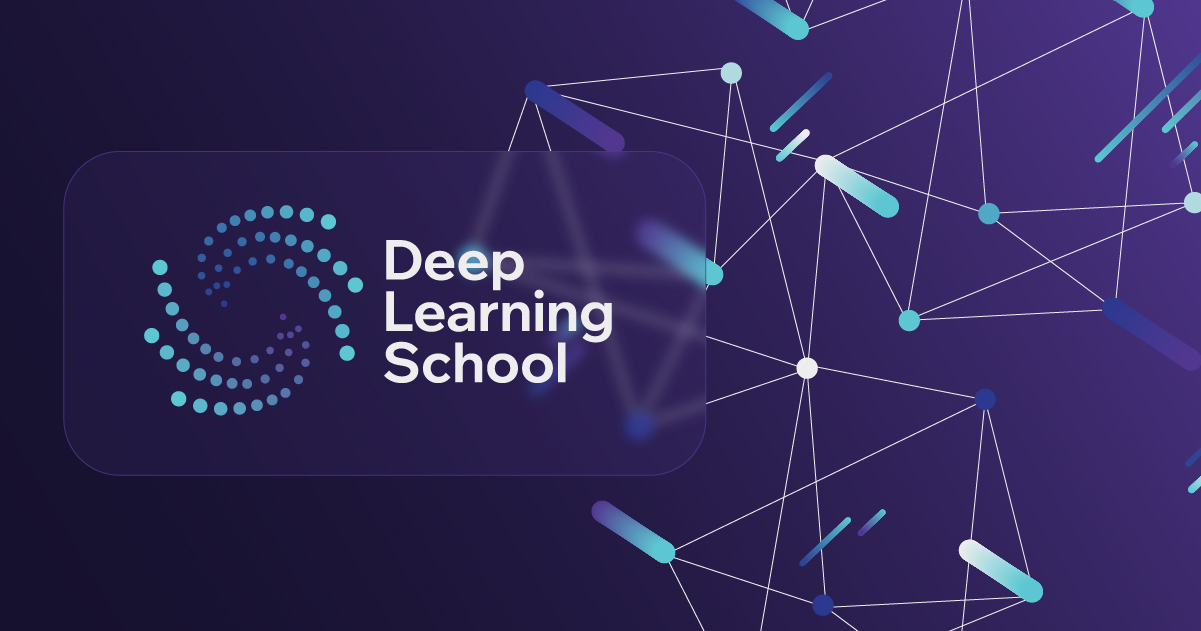

# Steering SDXL

Notebook author: **Nina Konovalova**

**mail**: nina.konovalova.k@gmail.com

**tg**: @AfeliaN

**tg-channel**: [t.me/reading_ai](https://t.me/reading_ai)

In this notebook we change model activations during generation to remove, add or swap a concept, without training.
This is **activation steering**.

Our task is to **erase Snoopy**, even when a prompt describes him without his name. A good eraser preserves similar
characters (Mickey Mouse, Pikachu, Charlie Brown), real beagles and images from unrelated prompts.

Every section ends with **Tasks**. Write your code in the empty cell under each task.

We use **SDXL-Turbo**, a distilled SDXL that draws a 512 px image in one step, so each experiment takes seconds.

> **GPU.** A free Colab **T4 (16 GB VRAM, 12.7 GB RAM)** is enough.

## 1. Setup and tools

We first set up our tools.

### Setup

First, install and import the libraries.

In [2]:
!pip -q install "diffusers>=0.30" transformers accelerate

In [4]:
import gc
import json
import math
import time

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from huggingface_hub import hf_hub_download
from diffusers import StableDiffusionXLPipeline, AutoencoderKL
from transformers import CLIPModel, CLIPTokenizer, CLIPImageProcessor

DEVICE = "cuda"
DTYPE = torch.float16
TURBO_ID = "stabilityai/sdxl-turbo"
VAE_ID = "madebyollin/sdxl-vae-fp16-fix"   # the original SDXL VAE overflows in fp16
CLIP_ID = "openai/clip-vit-base-patch32"    # the judge
SAE_REPO = "surokpro2/sdxl-saes"            # §4
VARIANT = "fp16"                            # fp16 weight files: half the download, fits Colab RAM
RES = 512                                   # SDXL-Turbo works at 512 px
STEPS = 1                                   # Turbo: 1-4 steps, no CFG
BATCH = 8                                   # images per pipeline call
SEED = 0
torch.set_grad_enabled(False)

torch.autograd.grad_mode.set_grad_enabled(mode=False)

We load SDXL-Turbo with a corrected SDXL VAE, since the original overflows in fp16.

In [6]:
def gpu_gb():
    """GPU memory in use, GB (0 on CPU)."""
    return torch.cuda.memory_allocated() / 2**30 if torch.cuda.is_available() else 0.0


# Load the pipeline
t0 = time.time()
pipe = StableDiffusionXLPipeline.from_pretrained(
    TURBO_ID, torch_dtype=DTYPE, variant=VARIANT,
    vae=AutoencoderKL.from_pretrained(VAE_ID, torch_dtype=DTYPE),
).to(DEVICE)
pipe.set_progress_bar_config(disable=True)
print(f"SDXL-Turbo loaded in {time.time() - t0:.0f} s, GPU memory {gpu_gb():.1f} GB")

SDXL-Turbo loaded in 13 s, GPU memory 6.6 GB


### Hooks and generation

We steer by changing layer outputs with PyTorch **forward hooks** while the U-Net runs:

| module | example name | output | what we use |
|---|---|---|---|
| cross-attention | `up_blocks.0.attentions.1.transformer_blocks.3.attn2` | $x \in \mathbb R^{B\times N\times C}$ | the text's contribution at each of the $N$ positions |
| transformer block | `up_blocks.0.attentions.1` | $h \in \mathbb R^{B\times C\times H\times W}$ | the **residual update** $\Delta h = h_\text{out} - h_\text{in}$ |

Here $B$ is batch size, $C$ is channels, and $H$ and $W$ are grid height and width. The diagram shows our hook points:

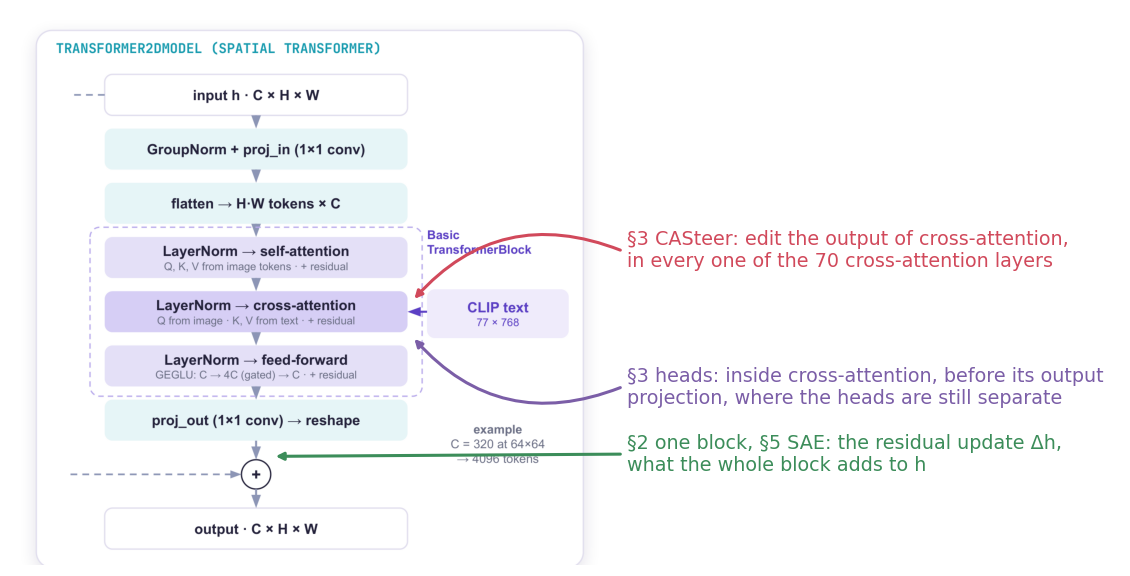

In [8]:
RUN = {"step": 0}   # current denoising step (set by `generate`)


def layer_names(unet):
    """(cross-attention layer names, transformer block names) of a U-Net, in the order it runs them: down, mid, up."""
    parts = ["down_blocks", "mid_block", "up_blocks"]
    mods = [(n, m) for n, m in unet.named_modules() if n.split(".")[0] in parts]
    mods = sorted(mods, key=lambda nm: parts.index(nm[0].split(".")[0]))   # stable: keeps the order inside a part
    return ([n for n, m in mods if n.endswith(".attn2")],
            [n for n, m in mods if type(m).__name__ == "Transformer2DModel"])


ATTN2, BLOCKS = layer_names(pipe.unet)
HOOKS = []   # handles of the hooks registered by the last `generate` call


def generate(prompts, seeds=SEED, hooks=None, steps=STEPS, res=RES, batch=BATCH, decode=True, **kw):
    """Generate one image per prompt (fixed seed per image), `batch` images per pipeline call.

    How: registers one PyTorch forward hook per entry of `hooks`, counts the steps in `callback_on_step_end`, and
    removes the hooks at the end (or at the start of the next call, if this one was interrupted).
    Args:
        prompts: a string or a list of strings; seeds: one int, or one seed per prompt
        hooks: {module name: f(x_in, x_out)}; f returns a new output tensor, or None to keep the output
        decode: False skips the VAE decoder (when we only need what the hooks record)
        **kw: passed to the pipeline
    Returns: list of PIL images (empty if decode=False)
    """
    prompts = [prompts] if isinstance(prompts, str) else list(prompts)
    seeds = [seeds] * len(prompts) if isinstance(seeds, int) else list(seeds)

    def as_forward_hook(f):
        # Define a forward hook function that will be called after every forward pass of the module.
        def hook(module, args, kwargs, out):
            x_in = args[0] if args else kwargs["hidden_states"]
            x_out = out[0] if isinstance(out, tuple) else out      # a block returns a tuple, attn2 a tensor
            new = f(x_in, x_out)
            if new is None:
                return None
            return (new, *out[1:]) if isinstance(out, tuple) else new
        return hook

    def on_step_end(pipe_, i, t, kwargs):
        RUN["step"] = i + 1
        return kwargs

    for h in HOOKS:                          # hooks of the previous call (still there if it was interrupted)
        h.remove()

    # Register forward hooks for the specified modules in the U-Net.
    modules = dict(pipe.unet.named_modules())
    HOOKS[:] = [modules[n].register_forward_hook(as_forward_hook(f), with_kwargs=True) for n, f in (hooks or {}).items()]
    images = []
    for i in range(0, len(prompts), batch):  # `batch` prompts per pipeline call
        RUN["step"] = 0
        chunk = prompts[i:i + batch]
        out = pipe(chunk, num_inference_steps=steps, guidance_scale=0.0, height=res, width=res,
                   generator=[torch.Generator("cpu").manual_seed(s) for s in seeds[i:i + batch]],
                   output_type="pil" if decode else "latent", callback_on_step_end=on_step_end, **kw)
        if decode:
            images += out.images
    for h in HOOKS:                          # leave the model clean
        h.remove()
    return images


def sweep(prompts, make_hooks, values, **gen_kw):
    """Generate every prompt under every value of a steering knob.

    make_hooks(value) returns the `hooks` for `generate` ({} = no steering).
    Returns: images row by row (one row per prompt, one column per value).
    """
    # Generate images for each value of the steering knob.
    cols = [generate(prompts, hooks=make_hooks(v), **gen_kw) for v in values]
    return [col[i] for i in range(len(prompts)) for col in cols]

Run the plotting helpers below. You can skip reading their code.

In [10]:
def short(name):
    """Short block name: 'up_blocks.0.attentions.1.transformer_blocks.3.attn2' -> 'up0.1'."""
    g = name.split(".transformer_blocks")[0]
    return (g.replace("down_blocks.", "down").replace("up_blocks.", "up").replace("mid_block", "mid")
             .replace(".attentions.", "."))


def show_grid(images, ncols, titles=None, row_labels=None, col_labels=None, size=2.2, suptitle=None):
    """Plot PIL images (row by row) in a grid with optional captions, row labels (left) and column labels (top)."""
    nrows = math.ceil(len(images) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(size * ncols, size * nrows + 0.4), squeeze=False)
    for k, ax in enumerate(axes.flat):
        ax.set_xticks([]); ax.set_yticks([])
        for s in ax.spines.values():
            s.set_visible(False)
        if k >= len(images):
            continue
        ax.imshow(images[k])
        r, c = divmod(k, ncols)
        top = col_labels[c] if (col_labels is not None and r == 0) else ""
        cap = titles[k] if titles else ""
        ax.set_title("\n".join(t for t in (top, cap) if t), fontsize=8)
        if row_labels is not None and c == 0:
            ax.set_ylabel(row_labels[r], fontsize=8)
    if suptitle:
        fig.suptitle(suptitle, fontsize=10)
    plt.tight_layout()
    plt.show()

### Collecting prompts

As in CASteer, we estimate a direction from prompt pairs that differ only by the concept:

- $p_i^+$ = `"{ImageNet class i} with Snoopy"`

- $p_i^-$ = `"{ImageNet class i}"`.

Averaging over many different objects cancels the objects, and what is left is mostly Snoopy.

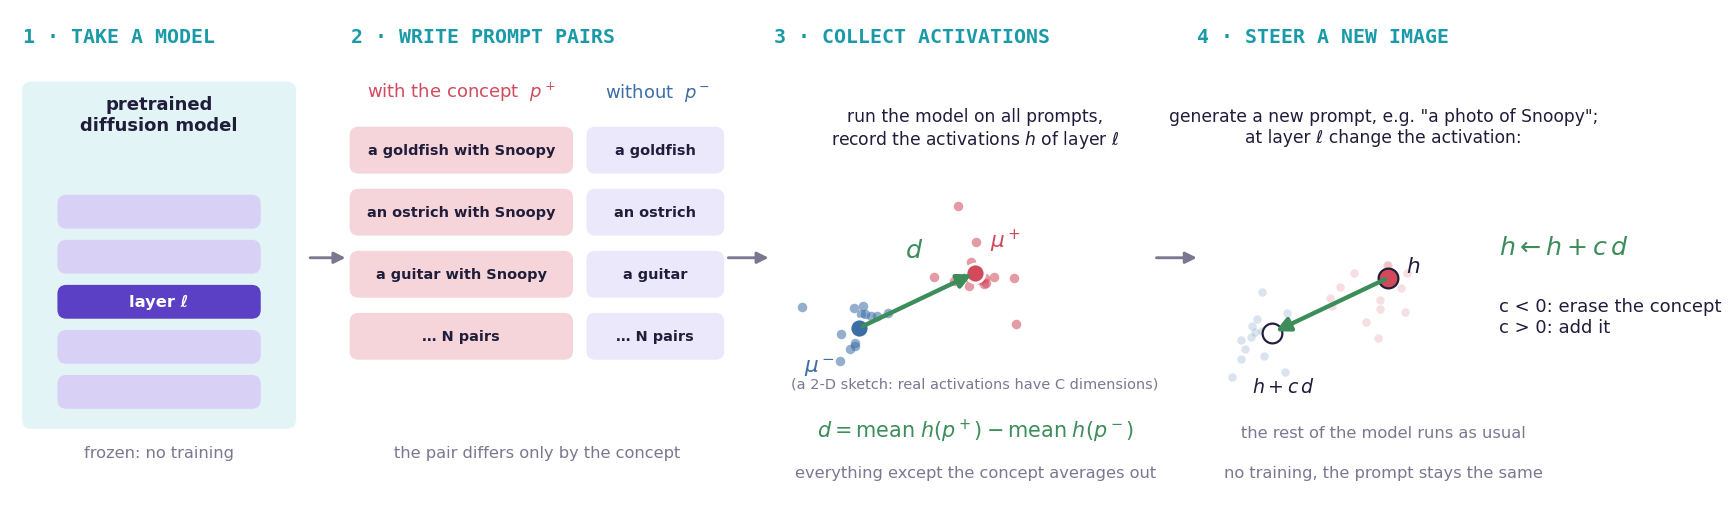

In [12]:
IMAGENET = [   # the first 100 ImageNet classes, as in CASteer's imagenet_classes.txt
    'tench', 'goldfish', 'great white shark', 'tiger shark', 'hammerhead', 'electric ray', 'stingray', 'cock', 'hen',
    'ostrich', 'brambling', 'goldfinch', 'house finch', 'junco', 'indigo bunting', 'robin', 'bulbul', 'jay',
    'magpie', 'chickadee', 'water ouzel', 'kite', 'bald eagle', 'vulture', 'great grey owl',
    'European fire salamander', 'common newt', 'eft', 'spotted salamander', 'axolotl', 'bullfrog', 'tree frog',
    'tailed frog', 'loggerhead', 'leatherback turtle', 'mud turtle', 'terrapin', 'box turtle', 'banded gecko',
    'common iguana', 'American chameleon', 'whiptail', 'agama', 'frilled lizard', 'alligator lizard', 'Gila monster',
    'green lizard', 'African chameleon', 'Komodo dragon', 'African crocodile', 'American alligator', 'triceratops',
    'thunder snake', 'ringneck snake', 'hognose snake', 'green snake', 'king snake', 'garter snake', 'water snake',
    'vine snake', 'night snake', 'boa constrictor', 'rock python', 'Indian cobra', 'green mamba', 'sea snake',
    'horned viper', 'diamondback', 'sidewinder', 'trilobite', 'harvestman', 'scorpion',
    'black and gold garden spider', 'barn spider', 'garden spider', 'black widow', 'tarantula', 'wolf spider',
    'tick', 'centipede', 'black grouse', 'ptarmigan', 'ruffed grouse', 'prairie chicken', 'peacock', 'quail',
    'partridge', 'African grey', 'macaw', 'sulphur-crested cockatoo', 'lorikeet', 'coucal', 'bee eater', 'hornbill',
    'hummingbird', 'jacamar', 'toucan', 'drake', 'red-breasted merganser', 'goose',
]

TARGET = "Snoopy"
NEIGHBOURS = ["Mickey Mouse", "Pikachu", "a beagle", "Charlie Brown"]
TEMPLATES = ["a photo of {}", "{} playing the guitar", "{} riding a skateboard", "a watercolor painting of {}",
             "{} in a park", "{} eating ice cream"]
UNRELATED = ["a red car on a city street", "a bowl of fruit on a wooden table", "a mountain lake at sunrise",
             "a portrait of an old man", "a cat sleeping on a sofa", "a city skyline at night"]
PARAPHRASES = ["the beagle from Peanuts", "Charlie Brown's dog", "the famous Peanuts comic strip dog",
               "a white cartoon beagle with black ears sleeping on top of a red doghouse",
               "Snoopie the cartoon dog"]


def concept_prompts(concept, n, template="{cls} with {concept}"):
    """The first n CASteer prompts: ["tench with Snoopy", "goldfish with Snoopy", ...]; concept=None gives the plain
    class names (the negative prompts)."""
    return [c if concept is None else template.format(cls=c, concept=concept) for c in IMAGENET[:n]]


print(concept_prompts(TARGET, 3), concept_prompts(None, 3))

['tench with Snoopy', 'goldfish with Snoopy', 'great white shark with Snoopy'] ['tench', 'goldfish', 'great white shark']


**What the pairs look like.** Here are four pairs, with the same seed within each pair. The top row shows $p^+$,
the bottom $p^-$.

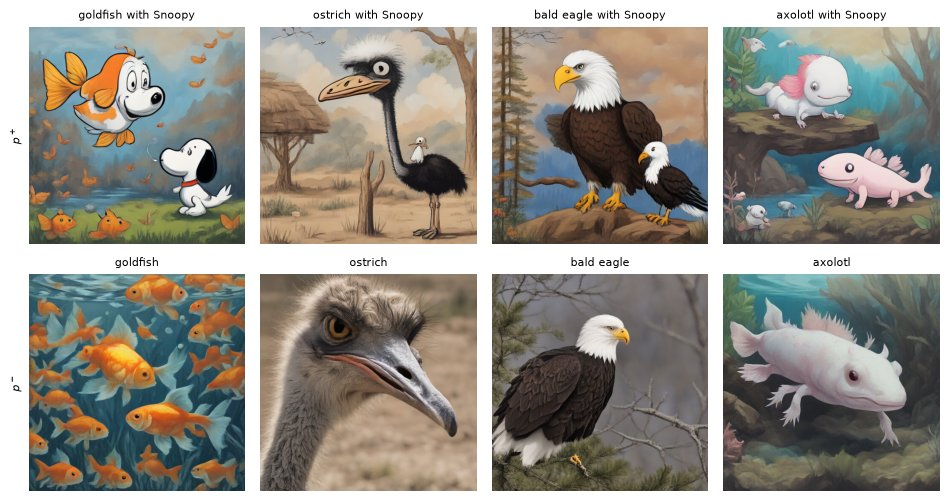

In [14]:
PAIR_CLASSES = ["goldfish", "ostrich", "bald eagle", "axolotl"]    # all among the first 32 classes we use
pos = [f"{c} with {TARGET}" for c in PAIR_CLASSES]
neg = PAIR_CLASSES
PAIR_IMGS = generate(pos + neg)
show_grid(PAIR_IMGS, len(PAIR_CLASSES), titles=pos + neg, row_labels=["$p^+$", "$p^-$"], size=2.4)

The pairs are noisy. Snoopy may stand next to the object (the goldfish) or appear tiny (the ostrich).
He may be absent, with the object drawn in his cartoon style instead (the eagle, the axolotl).
The $p^-$ images are mostly photos. So $p^+ - p^-$ captures both *Snoopy* and *"a Peanuts-like cartoon"*.
How to build good pairs is itself a useful research question.

### The judge (CLIP zero-shot)

We use CLIP to check hundreds of images for Snoopy.

For image $I$ and label set $L$ (target, neighbours and generic labels), we compare image and text embeddings
$E_\text{img}$ and $E_\text{txt}$ by cosine similarity. For each label $l$:

$$P(l \mid I) = \operatorname{softmax}_{l \in L}\big(100 \cdot \cos(E_\text{img}(I),\ E_\text{txt}(\text{"a picture of } l\text{"}))\big).$$

`judge_titles` shows $P(\text{Snoopy})$ above each image.

In [16]:
clip_model = CLIPModel.from_pretrained(CLIP_ID, torch_dtype=DTYPE).to(DEVICE).eval()
clip_tok = CLIPTokenizer.from_pretrained(CLIP_ID)
clip_px = CLIPImageProcessor.from_pretrained(CLIP_ID)
LABELS = [TARGET] + NEIGHBOURS + ["a cat", "a person", "a toy", "a landscape", "a car", "food", "a building"]


def clip_images(images):
    """CLIP embeddings of PIL images: [n, 512], unit norm, float32 on CPU."""
    out = []
    for i in range(0, len(images), 32):
        px = clip_px(images=images[i:i + 32], return_tensors="pt").pixel_values.to(DEVICE, DTYPE)
        e = clip_model.visual_projection(clip_model.vision_model(pixel_values=px).pooler_output)
        out.append(F.normalize(e.float(), dim=-1).cpu())
    return torch.cat(out)


def clip_texts(texts):
    """CLIP embeddings of strings: [n, 512], unit norm, float32 on CPU."""
    t = clip_tok(texts, padding=True, return_tensors="pt").to(DEVICE)
    e = clip_model.text_projection(clip_model.text_model(input_ids=t.input_ids, attention_mask=t.attention_mask).pooler_output)
    return F.normalize(e.float(), dim=-1).cpu()


LABEL_EMB = clip_texts([f"a picture of {l}" for l in LABELS])


def zero_shot(images):
    """P(label | image) over LABELS for PIL images (or their CLIP embeddings): [n, len(LABELS)], column 0 = P(Snoopy)."""
    emb = images if torch.is_tensor(images) else clip_images(images)
    return (100.0 * emb @ LABEL_EMB.T).softmax(-1).numpy()


def judge_titles(images, labels=(TARGET,)):
    """One caption per image: 'P(Snoopy) = ...', the CLIP probability of each label in `labels`."""
    P = zero_shot(images)
    cols = [LABELS.index(l) for l in labels]
    return ["\n".join(f"P({l}) = {p[k]:.2f}" for l, k in zip(labels, cols)) for p in P]

**The judge on the pairs.** Each chart shows the full label distribution $P(l \mid I)$ for the image above it.
Snoopy is red.

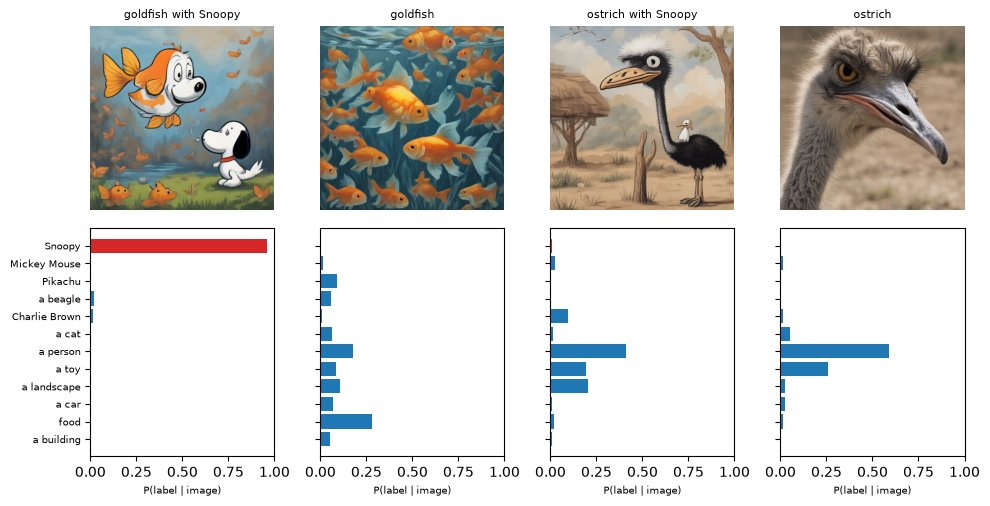

In [18]:
def show_judge(images, titles):
    """Each image above a bar chart of its CLIP distribution P(label | image) over LABELS (Snoopy in red)."""
    P = zero_shot(images)
    fig, axes = plt.subplots(2, len(images), figsize=(2.5 * len(images), 5.2), gridspec_kw={"height_ratios": [1, 1.2]})
    for k, (im, p) in enumerate(zip(images, P)):
        axes[0, k].imshow(im); axes[0, k].axis("off"); axes[0, k].set_title(titles[k], fontsize=8)
        axes[1, k].barh(range(len(LABELS)), p, color=["C3"] + ["C0"] * (len(LABELS) - 1))
        axes[1, k].set_yticks(range(len(LABELS)), LABELS if k == 0 else [], fontsize=7)
        axes[1, k].invert_yaxis(); axes[1, k].set_xlim(0, 1); axes[1, k].set_xlabel("P(label | image)", fontsize=7)
    plt.tight_layout(); plt.show()


order = [0, 4, 1, 5]                       # goldfish: p+, p-; ostrich: p+, p-
show_judge([PAIR_IMGS[i] for i in order], [(pos + neg)[i] for i in order])

Three things to notice:

* When Snoopy is clearly visible, the judge assigns almost all probability to Snoopy.
* Softmax distributes probability over $L$. Without "goldfish" or "ostrich", it assigns the plain images to the
  closest labels: "food", "a person", "a toy". Those labels are not meaningful here. We use only $P(\text{Snoopy})$.
* The judge scores the whole image, so a small Snoopy (the ostrich pair) gets $P(\text{Snoopy}) \approx 0$.
  This is fine for our tasks: the Snoopy test prompts draw him large.

**Two helpers for measuring.** In every task, `p_label` returns one label's probability. `similarity` compares
steered and unsteered images with the same prompt and seed. A good eraser lowers `p_label(..., "Snoopy")` on Snoopy
prompts and keeps `similarity` close to 1 on everything else.

In [20]:
def p_label(images, label=TARGET):
    """CLIP probability of `label` (one of LABELS) for each image: [n] numpy array."""
    return zero_shot(images)[:, LABELS.index(label)]


def similarity(images, ref_images):
    """CLIP image-image cosine of each image to its reference image: [n] numpy array (1 = the same for CLIP)."""
    return (clip_images(images) * clip_images(ref_images)).sum(-1).numpy()


print("P(Snoopy) on the pairs:", p_label(PAIR_IMGS).round(2))
print("similarity of p+ to p- images:", similarity(PAIR_IMGS[:4], PAIR_IMGS[4:]).round(2))

P(Snoopy) on the pairs: [0.96 0.01 0.02 0.06 0.   0.   0.02 0.  ]
similarity of p+ to p- images: [0.65 0.84 0.86 0.89]


## 2. The simplest idea: one Snoopy direction in one block

Step by step:

1. Record the residual update $\Delta h_\ell$ of one transformer block $\ell$ for $N$ prompt pairs.
2. Average it over the $H \times W$ positions ($\overline{\Delta h}$) and over the prompts, and take the difference:

$$d_\ell = \frac1N\sum_{i=1}^N \overline{\Delta h_\ell}(p_i^+) - \frac1N\sum_{i=1}^N \overline{\Delta h_\ell}(p_i^-);$$

3. Use coefficient $c$ to steer every position: $\Delta h_\ell \leftarrow \Delta h_\ell + c\, d_\ell$, with $c < 0$ to
   erase and $c > 0$ to add.

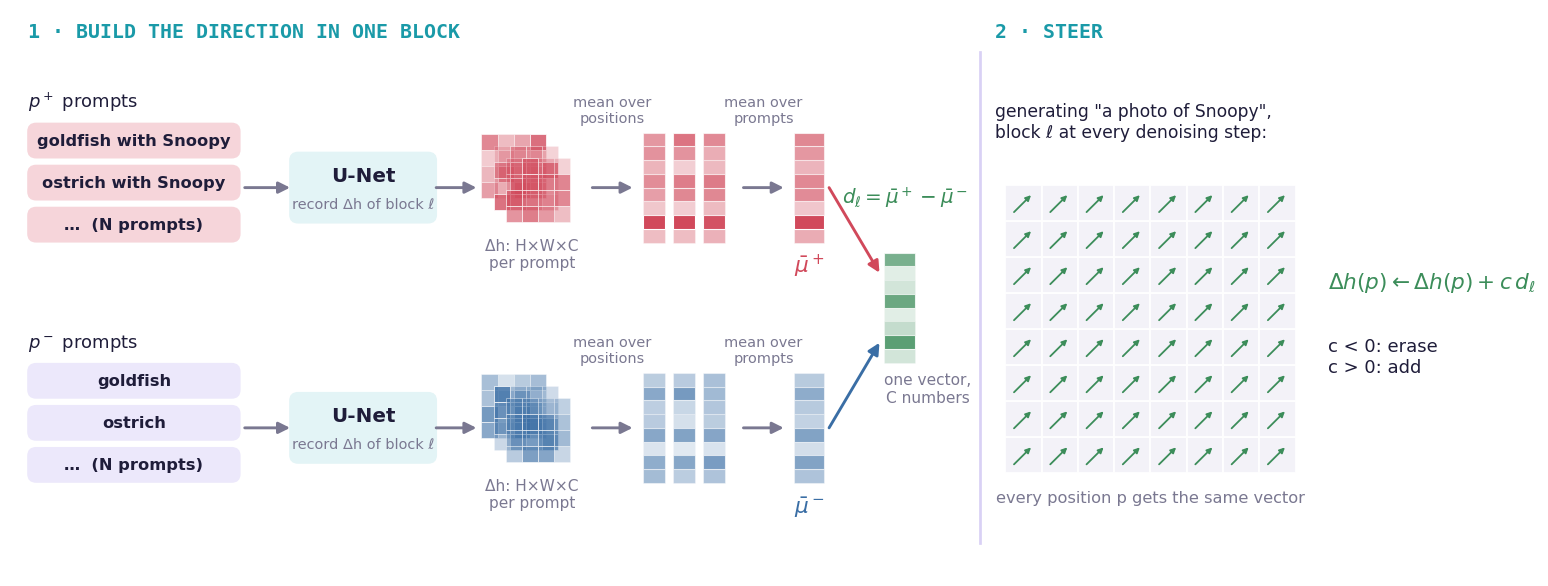

In [22]:
BLOCK = "up_blocks.0.attentions.1"
N_PAIRS = 32
print("transformer blocks:", ", ".join(short(b) for b in BLOCKS))


def block_update(prompts, block=None, seeds=SEED, decode=False):
    """Residual update Δh = output - input of `block` (default: BLOCK) for every prompt.

    Returns: (updates [n, H, W, C] float32 on CPU, channels last as the SAE of §4 expects;
              images, empty unless decode=True).
    """
    ups = []

    def record(x_in, x_out):
        ups.append((x_out - x_in).float().permute(0, 2, 3, 1).cpu())

    images = generate(prompts, seeds, hooks={block or BLOCK: record}, decode=decode)
    return torch.cat(ups), images


def add_to_block(vec, coef, block=None):
    """Hooks for `generate`: Δh <- Δh + coef * vec at every position of `block` (default: BLOCK).
    coef < 0 erases, > 0 adds."""
    v = vec.to(DEVICE)

    def add(x_in, x_out):
        return x_out + (coef * v).to(x_out.dtype)[:, None, None]

    return {block or BLOCK: add}


U_pos, _ = block_update(concept_prompts(TARGET, N_PAIRS))
U_neg, _ = block_update(concept_prompts(None, N_PAIRS))
d_block = U_pos.mean((0, 1, 2)) - U_neg.mean((0, 1, 2))          # mean over prompts and positions

transformer blocks: down1.0, down1.1, down2.0, down2.1, mid.0, up0.0, up0.1, up0.2, up1.0, up1.1, up1.2


**Erase and add.**

In the first grid, we subtract direction $d$ more strongly as coefficient $c$ becomes more negative.
In the second, we add it to prompts without Snoopy. The judge shows $P(\text{Snoopy})$ above each image.
Does $P(\text{Snoopy})$ fall on the Snoopy rows? Do Mickey and the car stay the same?

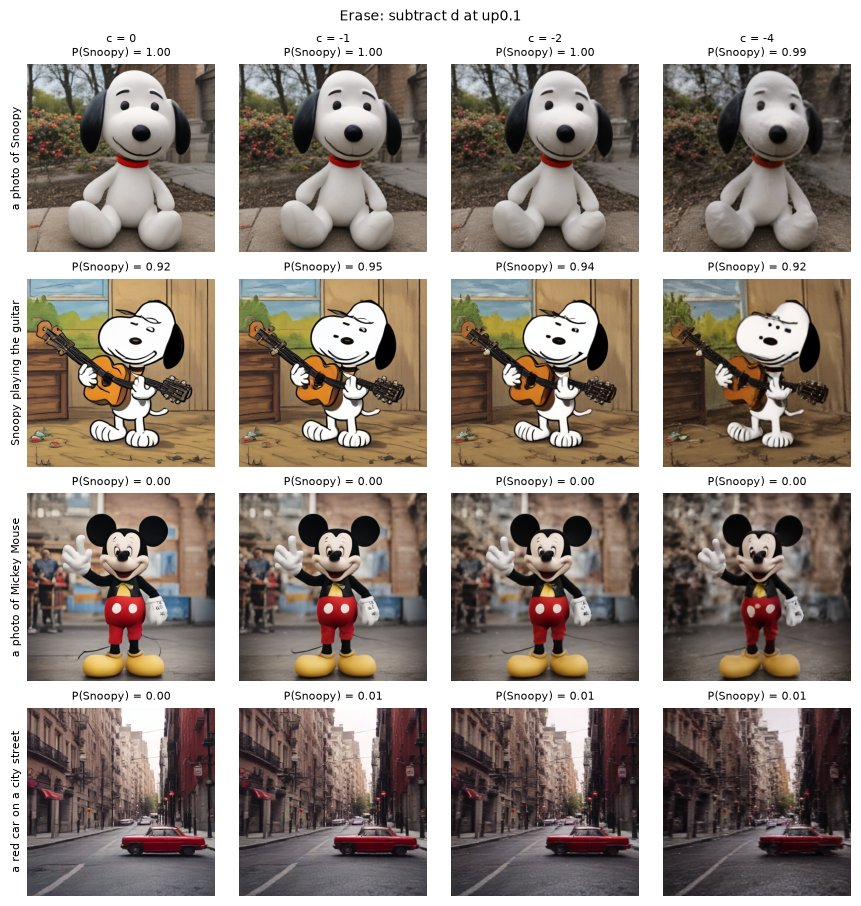

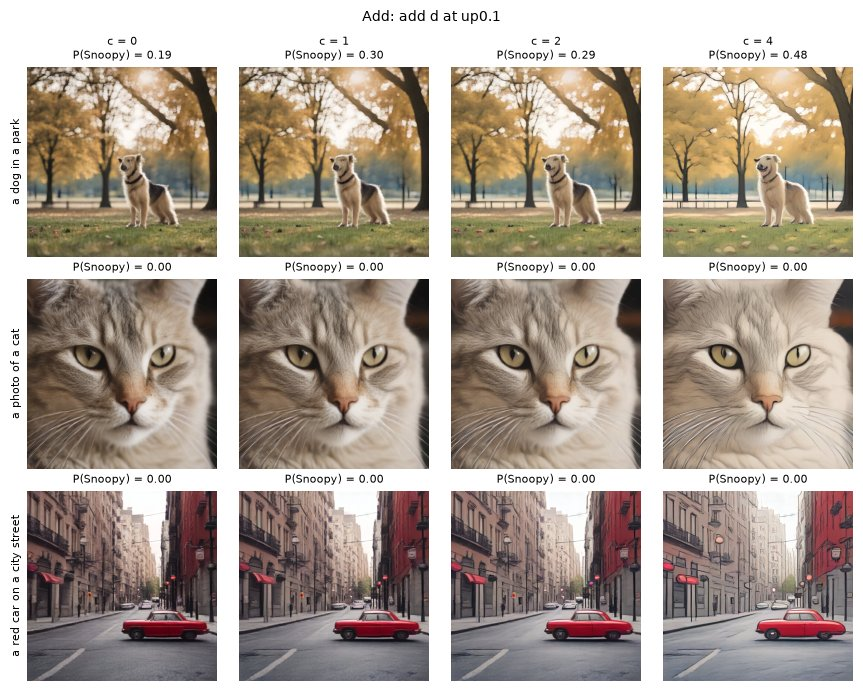

In [24]:
COEFS = [0, -1, -2, -4]
DEMO = ["a photo of Snoopy", "Snoopy playing the guitar", "a photo of Mickey Mouse", "a red car on a city street"]
imgs = sweep(DEMO, lambda c: add_to_block(d_block, c), COEFS)
show_grid(imgs, len(COEFS), judge_titles(imgs), row_labels=DEMO, col_labels=[f"c = {c}" for c in COEFS],
          suptitle=f"Erase: subtract d at {short(BLOCK)}")

ADD_COEFS = [0, 1, 2, 4]
ADD_DEMO = ["a dog in a park", "a photo of a cat", "a red car on a city street"]
imgs = sweep(ADD_DEMO, lambda c: add_to_block(d_block, c), ADD_COEFS)
show_grid(imgs, len(ADD_COEFS), judge_titles(imgs), row_labels=ADD_DEMO, col_labels=[f"c = {c}" for c in ADD_COEFS],
          suptitle=f"Add: add d at {short(BLOCK)}")

**What we see.** One direction in one block is **not enough**:

* **Erasing does not work.** At $c = -4$, Snoopy remains ($P(\text{Snoopy}) \approx 1$), but the image starts to blur.
  Mickey and the car stay unchanged because the edit has little effect overall.
* **Adding works only weakly.** At $c = 4$, the dog's $P(\text{Snoopy})$ rises, but it still looks like an ordinary dog.
  The cat and car do not change at all.

The prompt still says *Snoopy*, and all 70 cross-attention layers read it. We shift only one block, so the layers
after it read *Snoopy* again and bring him back.

We therefore steer **every** cross-attention layer, and only **where Snoopy is**.

### Tasks §2

**2.1 · Which block, and how strong?** The demo steered *up0.1*. Repeat it for all 11 blocks in `BLOCKS`,
**one block at a time**. Estimate a separate direction for each block and leave all other blocks untouched.
For each block `b`:

1. Compute $d_b$: call `block_update(...)` with `block=b` for the $p^+$ and $p^-$ prompts, average over prompts and
   positions, then subtract the negative mean from the positive mean.
2. **Erase:** fill the three `TEMPLATES[:3]` with Snoopy. Generate images with `hooks=add_to_block(d_b, c, block=b)`
   for $c \in \{0, -1, -2, -4, -8\}$. Measure mean $P(\text{Snoopy})$ with `p_label`.
3. **Add:** generate `"a dog in a park"` with $c \in \{0, 1, 2, 4, 8\}$ and measure the same probability.

Plot $P(\text{Snoopy})$ against $|c|$ separately for erase and add. Use one line per block (11 lines), coloured by
U-Net part (down / mid / up). Which blocks respond? Inspect a few images: does erasing work before image quality
breaks down? Is adding easier than erasing? Why might that be?

*Bonus, more steps.* SDXL-Turbo is distilled for 1 to 4 denoising steps. We use one (`STEPS = 1`).
Hooks act at every step, so `generate(..., steps=4)` adds the same $d_b$ four times, once per step.
Repeat your best block's erase curve with `steps=4`. Is Snoopy easier to erase?

In [ ]:
# Task 2.1: your code


**2.2 · Collateral damage.** Subtracting $d$ at every position also changes images without Snoopy. Generate images for
`UNRELATED` with $c \in \{0, -2, -4\}$ and compute `similarity` to the $c = 0$ images. How could we change the
method to preserve unrelated images? (§3 gives one answer.)

In [28]:
# Task 2.2: your code


## 3. CASteer: steer every cross-attention layer, only where Snoopy is

One vector in one block has little effect here. [CASteer](https://arxiv.org/abs/2503.09630)
([code](https://github.com/Atmyre/CASteer)) changes two things:

* **Where:** text enters the U-Net mainly through cross-attention. CASteer edits **every** `attn2` output:
  70 layers in SDXL, one vector per layer.
* **How:** remove the Snoopy component only where it is present, leaving positions without Snoopy unchanged.

Step by step:

1. For layer $\ell$, average output $x_\ell(p) \in \mathbb R^C$ over positions $p$ and each set of prompts.
   Normalize the difference to get direction $b_\ell$:

$$\bar\mu^\pm_\ell = \frac1N\sum_{i=1}^N \operatorname{mean}_p\, x_\ell(p;\, p_i^\pm), \qquad
b_\ell = \frac{\bar\mu^+_\ell - \bar\mu^-_\ell}{\lVert\bar\mu^+_\ell - \bar\mu^-_\ell\rVert};$$

2. Edit each position using one of three rules:

| edit | rule at every position | note |
|---|---|---|
| **erase** (Eq. 6) | $\alpha = \max(\langle x, b_\ell\rangle, 0),\quad x \leftarrow x - \beta\,\alpha\, b_\ell$ | $\beta = 1$ removes the component, $\beta = 2$ reflects it. Positions without Snoopy ($\langle x, b\rangle \le 0$) are untouched |
| **add** | $x \leftarrow x + \alpha\,(\bar\mu^+_\ell - \bar\mu^-_\ell)$ | use the raw difference because the unit $b_\ell$ is tiny next to $\lVert x\rVert$ |
| **switch** A → B | erase with $b_\ell = \operatorname{normalize}(b^A_\ell - b^B_\ell)$ | reflect the A-component towards B |

**Cross-attention and how CASteer steers it.** Left: cross-attention computes a text contribution $x(p)$ for each
image position. Right: CASteer measures the component along the Snoopy direction $b$ and removes it.
Positions without Snoopy stay unchanged.

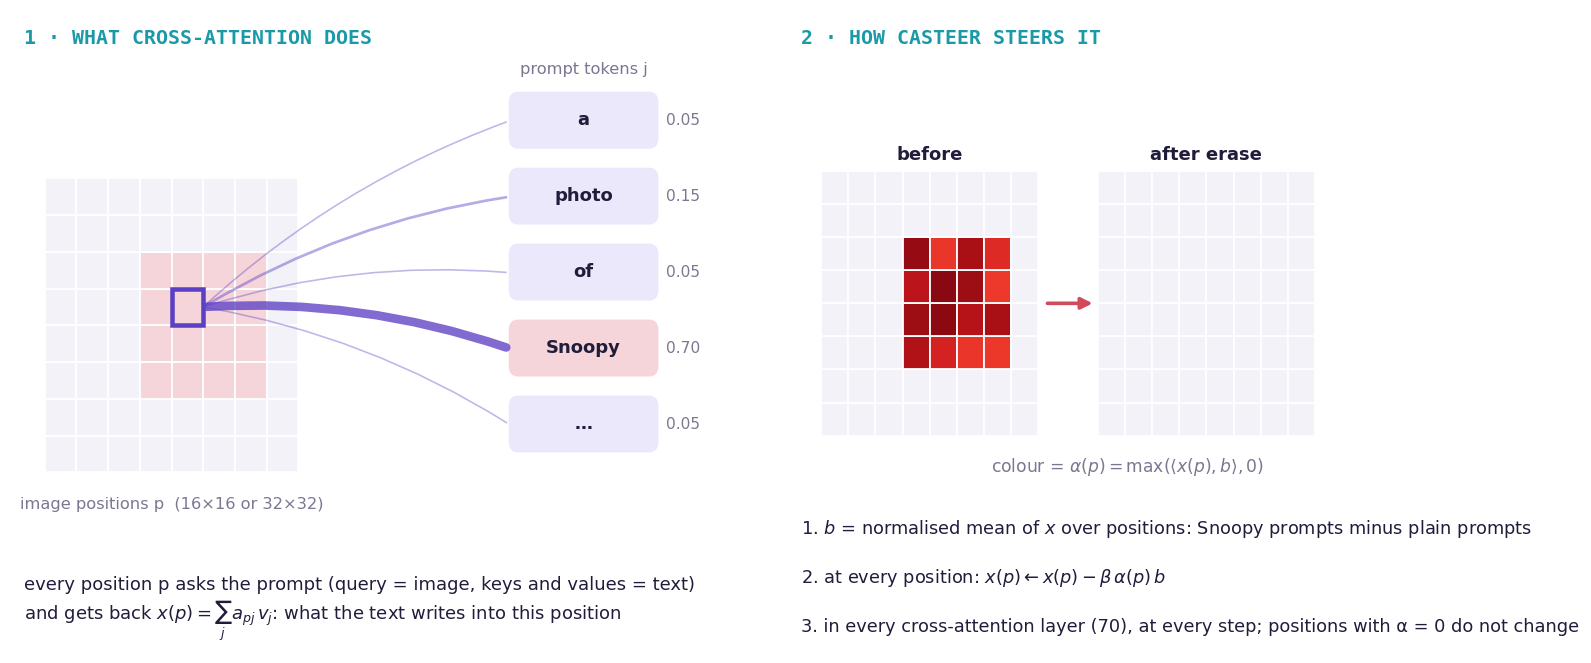

This figure from the CASteer paper shows the same method. Bottom left: for layer $i$, subtract the negative prompt's
cross-attention output from the positive prompt's output, averaging over patches. Right: use this vector to edit
that layer's cross-attention output at every generation step.

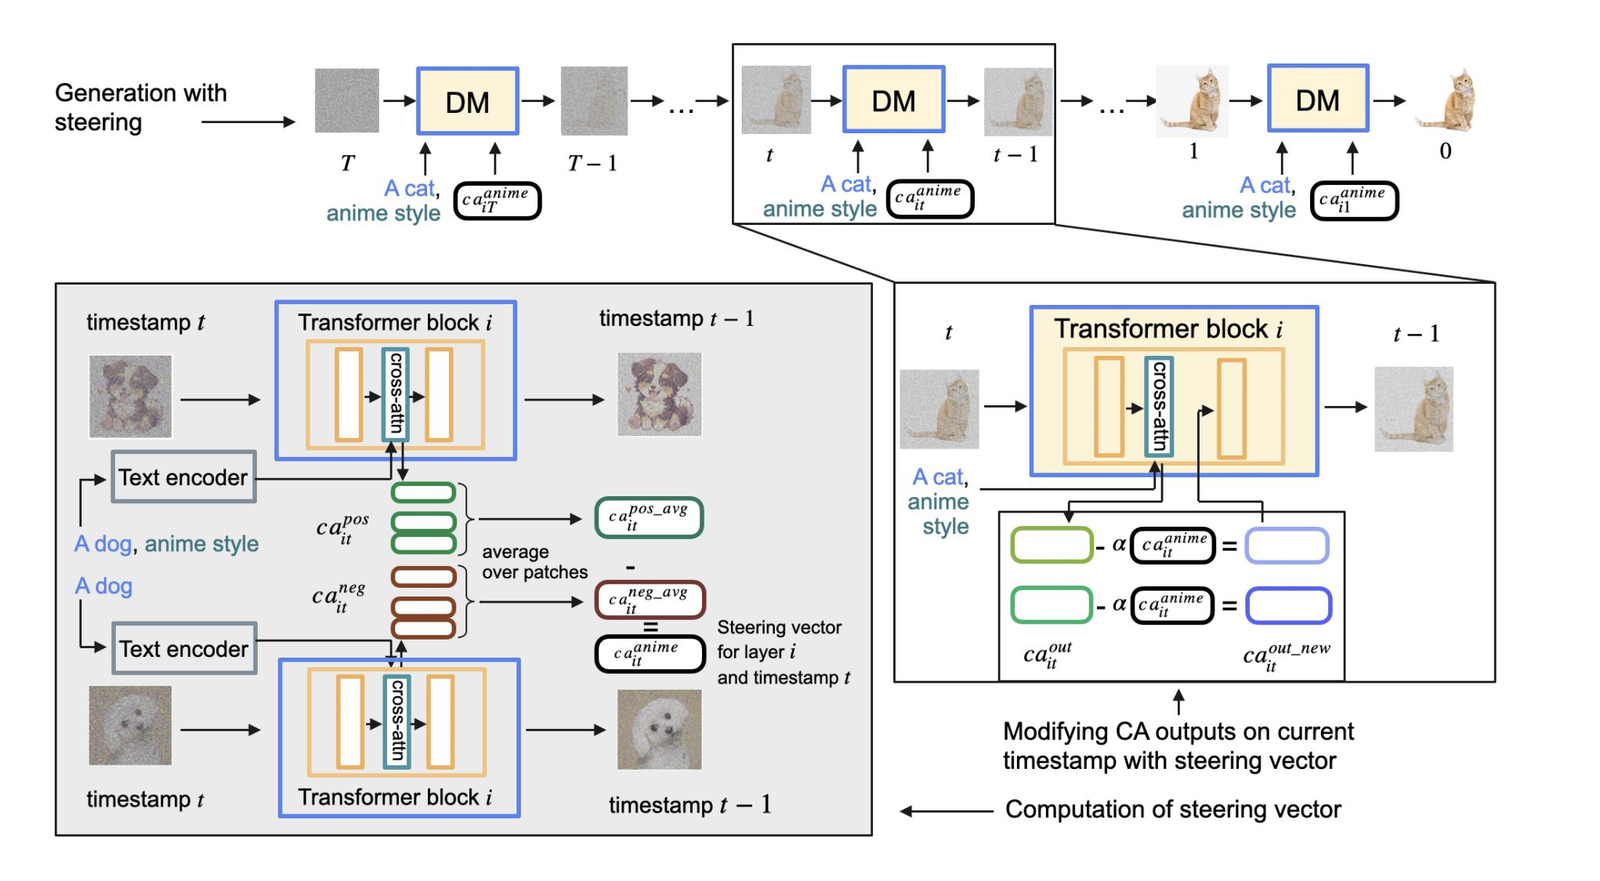

In [30]:
N_PAIRS_CA = 50
print(len(ATTN2), "cross-attention layers in", len({short(n) for n in ATTN2}), "blocks")


def attn2_means(prompts, seeds=SEED, **gen_kw):
    """Mean output of every cross-attention layer, over image positions, prompts (and steps): {layer: [C] on CPU}.

    These are CASteer's statistics (attn2 output averaged over tokens, then over prompts).
    """
    means = {n: [] for n in ATTN2}      # layer -> list of [b, C] means over positions

    def recorder(name):
        def record(x_in, x_out):
            means[name].append(x_out.float().mean(dim=1).cpu())
        return record

    generate(prompts, seeds, hooks={n: recorder(n) for n in ATTN2}, decode=False, **gen_kw)
    return {n: torch.cat(m).mean(0) for n, m in means.items()}


def direction(mu_a, mu_b):
    """b = normalize(mu_a - mu_b) for every layer: {layer: [C] unit vector}."""
    return {n: F.normalize(mu_a[n] - mu_b[n], dim=0) for n in mu_a}


def project_out(x, b, beta=2.0, clip=True):
    """CASteer Eq. 6 on the last dimension of x: alpha = max(<x, b>, 0), x <- x - beta * alpha * b (in float32).

    clip=False uses alpha = <x, b> also where it is negative.
    """
    xf, b = x.float(), b.to(x.device, torch.float32)
    alpha = xf @ b
    if clip:
        alpha = alpha.clamp_min(0)
    return (xf - beta * alpha[..., None] * b).to(x.dtype)


def casteer(B, beta=2.0, layers=None, at_steps=None, clip=True):
    """Hooks for `generate` that apply Eq. 6 to the cross-attention outputs (erase, or switch with a switch direction).

    Args:
        B: {layer: [C] unit direction}
        layers: None = all 70 layers, or name prefixes, e.g. ["up_blocks.0"]
        at_steps: None = every denoising step, or a set of 0-based step indices to steer
        clip: see `project_out`
    """
    def steer(name):
        def fn(x_in, x):
            if at_steps is not None and RUN["step"] not in at_steps:
                return None
            return project_out(x, B[name], beta, clip)
        return fn

    return {n: steer(n) for n in ATTN2 if layers is None or any(n.startswith(p) for p in layers)}


def casteer_add(D, alpha, layers=None):
    """Hooks for `generate` that add a concept: x <- x + alpha * D[layer] at every position of every attn2 layer
    (or only in the layers whose names start with one of `layers`)."""
    def add(name):
        def fn(x_in, x):
            return (x.float() + alpha * D[name].to(x.device)).to(x.dtype)
        return fn

    return {n: add(n) for n in ATTN2 if layers is None or any(n.startswith(p) for p in layers)}

70 cross-attention layers in 11 blocks


**Estimate the vectors** from 3 × 50 prompts: with Snoopy, without a concept, and with Pikachu for switching.
Use the means to compute the three edits above:

1. `B_ERASE` (erase).
2. `D_ADD` (add).
3. `B_SWITCH` (Snoopy → Pikachu).

In [32]:
t0 = time.time()
mu = {c: attn2_means(concept_prompts(c, N_PAIRS_CA)) for c in [TARGET, None, "Pikachu"]}
print(f"{3 * N_PAIRS_CA} prompts recorded in {time.time() - t0:.0f} s")

B_ERASE = direction(mu[TARGET], mu[None])                # erase Snoopy
D_ADD = {n: mu[TARGET][n] - mu[None][n] for n in ATTN2}  # add Snoopy (raw difference)
B_SWITCH = direction(B_ERASE, direction(mu["Pikachu"], mu[None]))   # Snoopy -> Pikachu

150 prompts recorded in 3 s


#### **Erase**

Each column uses a different steering strength $\beta$.

Compare the Snoopy rows with *the beagle from Peanuts*, which never names Snoopy, and with the neighbours.

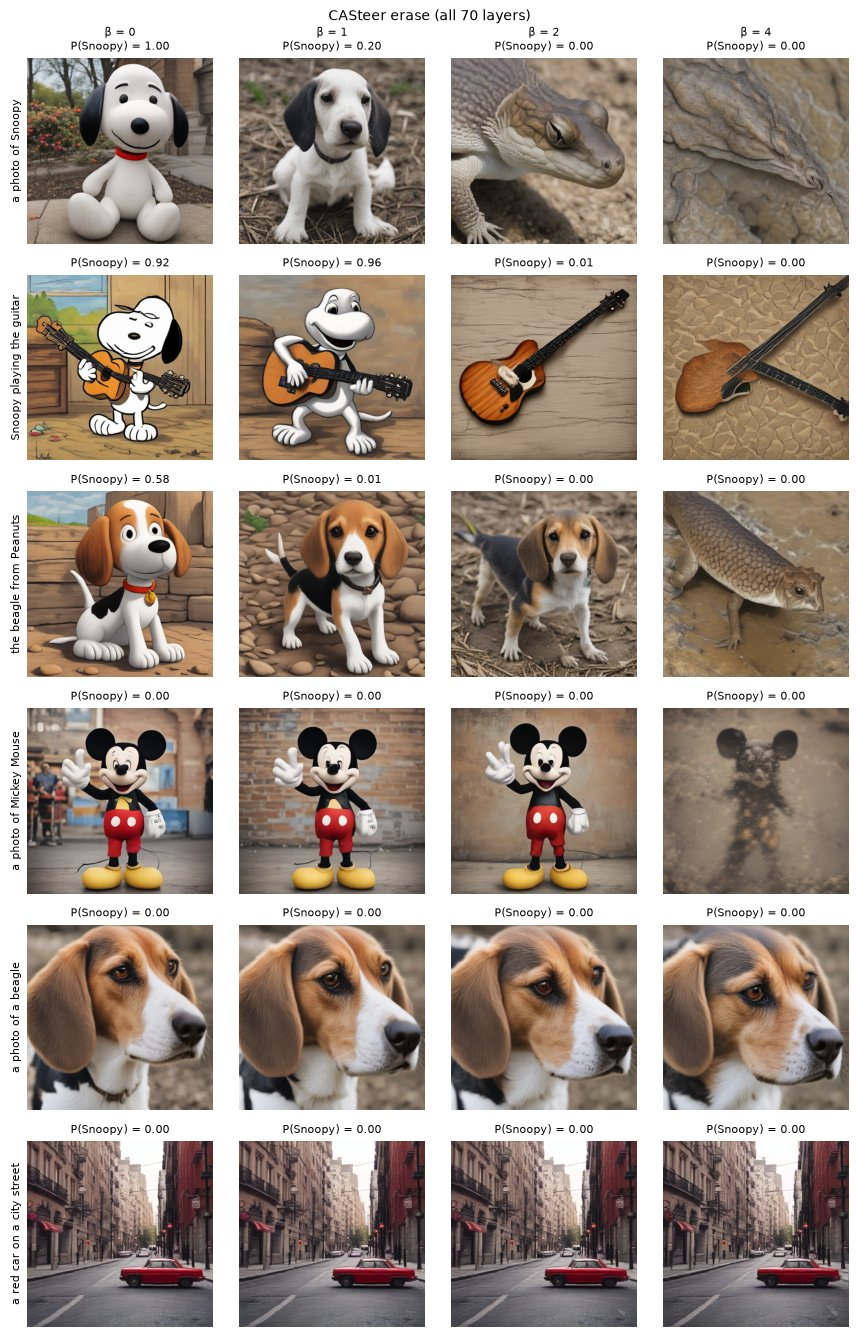

In [34]:
BETAS = [0, 1, 2, 4]
DEMO = ["a photo of Snoopy", "Snoopy playing the guitar", "the beagle from Peanuts", "a photo of Mickey Mouse",
        "a photo of a beagle", "a red car on a city street"]
imgs = sweep(DEMO, lambda b: casteer(B_ERASE, beta=b), BETAS)
show_grid(imgs, len(BETAS), judge_titles(imgs), row_labels=DEMO, col_labels=[f"β = {b}" for b in BETAS],
          suptitle="CASteer erase (all 70 layers)")

#### **Add**

Now add Snoopy to images whose prompts never mention him. At every position of every `attn2` layer, add the same vector:

$$x \leftarrow x + \alpha\,(\bar\mu^+_\ell - \bar\mu^-_\ell).$$

With $\alpha = 1$, each layer gets the average shift caused by the word *Snoopy*.

* We do not clip when adding. Erasing affects only positions with a Snoopy component. Adding has no such check,
  so we shift every position: the dog, the background and the car.

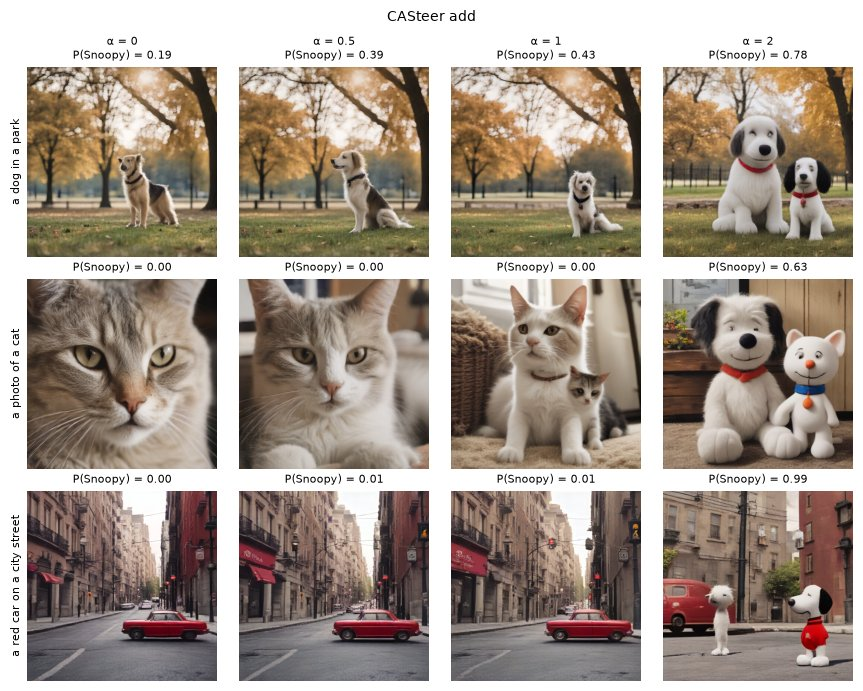

In [36]:
ALPHAS = [0, 0.5, 1, 2]
ADD_DEMO = ["a dog in a park", "a photo of a cat", "a red car on a city street"]
imgs = sweep(ADD_DEMO, lambda a: casteer_add(D_ADD, a), ALPHAS)
show_grid(imgs, len(ALPHAS), judge_titles(imgs), row_labels=ADD_DEMO, col_labels=[f"α = {a}" for a in ALPHAS],
          suptitle="CASteer add")

The dog turns into Snoopy step by step, and $P(\text{Snoopy})$ grows with $\alpha$. The cat and the car stay up to
$\alpha = 1$, and at $\alpha = 2$ Snoopy appears there too. Adding the vector at every layer and position overrides
the prompt.

#### **Switch Snoopy → Pikachu** 

The switch uses the erase rule (Eq. 6) along a different axis: the difference between the Snoopy and Pikachu directions.

$$b_\ell = \operatorname{normalize}\big(b^\text{Snoopy}_\ell - b^\text{Pikachu}_\ell\big).$$

Moving along $b_\ell$ means more Snoopy and less Pikachu. We apply the rule where
$\alpha = \langle x, b_\ell\rangle > 0$.

The judge shows $P(\text{Snoopy})$ and $P(\text{Pikachu})$ above each image.

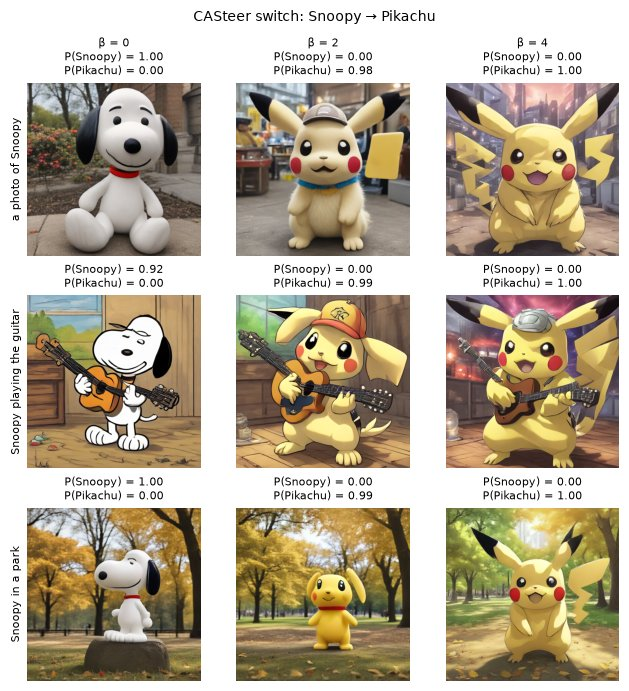

In [38]:
SWITCH_BETAS = [0, 2, 4]
SWITCH_DEMO = ["a photo of Snoopy", "Snoopy playing the guitar", "Snoopy in a park"]
imgs = sweep(SWITCH_DEMO, lambda b: casteer(B_SWITCH, beta=b), SWITCH_BETAS)
show_grid(imgs, len(SWITCH_BETAS), judge_titles(imgs, (TARGET, "Pikachu")), row_labels=SWITCH_DEMO,
          col_labels=[f"β = {b}" for b in SWITCH_BETAS], suptitle="CASteer switch: Snoopy → Pikachu")

At $\beta = 2$, every Snoopy becomes Pikachu while the guitar, park and pose stay the same.
At $\beta = 4$, the edit goes too far: Pikachu looks more exaggerated and the background starts to change.

#### **Heads: does every part of a cross-attention layer respond to Snoopy?**

A cross-attention layer has $H$ **heads** working in parallel: 10 in 640-channel layers, 20 in 1280-channel layers.
Each head has its own 64-channel queries, keys and values. It independently weights the prompt words at each image
position $p$ and returns a 64-channel output $o_h(p)$, where $h$ identifies the head. We concatenate these outputs,
then `to_out` mixes them using weights $W_\text{out}$ and bias $b_\text{out}$:

$$x(p) = W_\text{out}\,\big[\,o_1(p) \,|\, o_2(p) \,|\, \dots \,|\, o_H(p)\,\big] + b_\text{out}.$$

CASteer edits $x$ after this mixing, so it cannot separate the heads. We hook the **input** of `to_out` to inspect
heads while each still has its own 64 channels. Then we apply CASteer per head:

1. Average $o_h$ over positions and prompts, separately with and without Snoopy. Subtract the means to get
   $\Delta\bar o_h$: how much Snoopy changes the head's output. Its direction is the head's Snoopy direction $b_h$.
2. Rank all heads by $\lVert\Delta\bar o_h\rVert$.
3. Apply Eq. 6 with $b_h$ only to selected heads. Since `to_out` is linear, a change $\delta$ to $o_h$ changes the layer
   output by $W_\text{out}\,\delta$. Our hook adds this to $x$.

Do all ~1300 heads respond to Snoopy, or do a few account for most of the response?
Compare the top-ranked heads with the same number of random heads.

What happens inside one cross-attention layer, and where the two kinds of edits act:

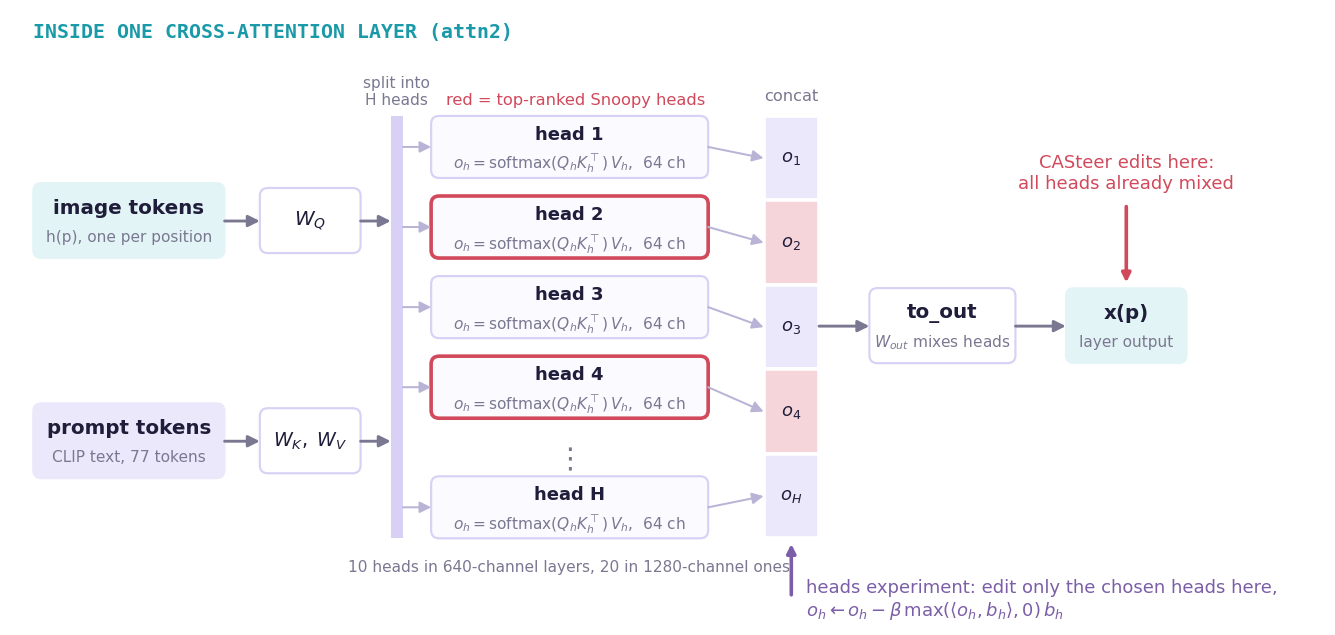

In [40]:
MODULES = dict(pipe.unet.named_modules())
HEADS = {n: MODULES[n].heads for n in ATTN2}          # number of heads in every cross-attention layer
print(sum(HEADS.values()), "heads in", len(HEADS), "cross-attention layers")


def head_means(prompts):
    """Mean answer of every head (the input of to_out) over positions and prompts: {layer: [H, C/H] on CPU}."""
    means = {n: [] for n in ATTN2}

    def recorder(name):
        def record(x_in, x_out):
            means[name].append(x_in.float().mean(dim=1).cpu())
        return record

    generate(prompts, hooks={n + ".to_out.0": recorder(n) for n in ATTN2}, decode=False)
    return {n: torch.cat(m).mean(0).unflatten(0, (HEADS[n], -1)) for n, m in means.items()}


def casteer_heads(heads, B, beta=2.0):
    """Hooks for `generate`: Eq. 6 on single heads, at the input of to_out.

    heads: list of (layer name, head index); B: {layer: [H, C/H] unit Snoopy direction of every head}.
    """
    chosen = {}
    for n, h in heads:
        chosen.setdefault(n, []).append(h)

    def steer(name, hs):
        W = MODULES[name + ".to_out.0"].weight                       # [C, C]
        b = B[name][hs].to(DEVICE)                                   # [k, C/H]

        def fn(x_in, x_out):
            o = x_in.float().unflatten(-1, (HEADS[name], -1))       # [batch, N, H, C/H]
            alpha = (o[:, :, hs] * b).sum(-1, keepdim=True).clamp_min(0)
            delta = torch.zeros_like(o)
            delta[:, :, hs] = -beta * alpha * b                      # Eq. 6, head by head
            return x_out + delta.flatten(-2).to(x_out.dtype) @ W.T   # to_out is linear: W(o + δ) + b = x + Wδ
        return fn

    return {n + ".to_out.0": steer(n, hs) for n, hs in chosen.items()}


mh = {c: head_means(concept_prompts(c, N_PAIRS_CA)) for c in [TARGET, None]}
B_HEADS = {n: F.normalize(mh[TARGET][n] - mh[None][n], dim=-1) for n in ATTN2}
size = {(n, h): float((mh[TARGET][n][h] - mh[None][n][h]).norm()) for n in ATTN2 for h in range(HEADS[n])}
RANKED = sorted(size, key=size.get, reverse=True)                    # heads, the most Snoopy-sensitive first
print("top-10 heads (block, layer, head):", ", ".join(f"{short(n)} L{n.split('.')[-2]} h{h}" for n, h in RANKED[:10]))

1300 heads in 70 cross-attention layers


top-10 heads (block, layer, head): down2.1 L1 h0, down2.1 L2 h15, down2.1 L7 h16, down2.1 L3 h8, down2.1 L0 h18, down2.1 L6 h9, down2.1 L1 h14, down2.1 L6 h18, down2.1 L5 h12, down2.1 L1 h17


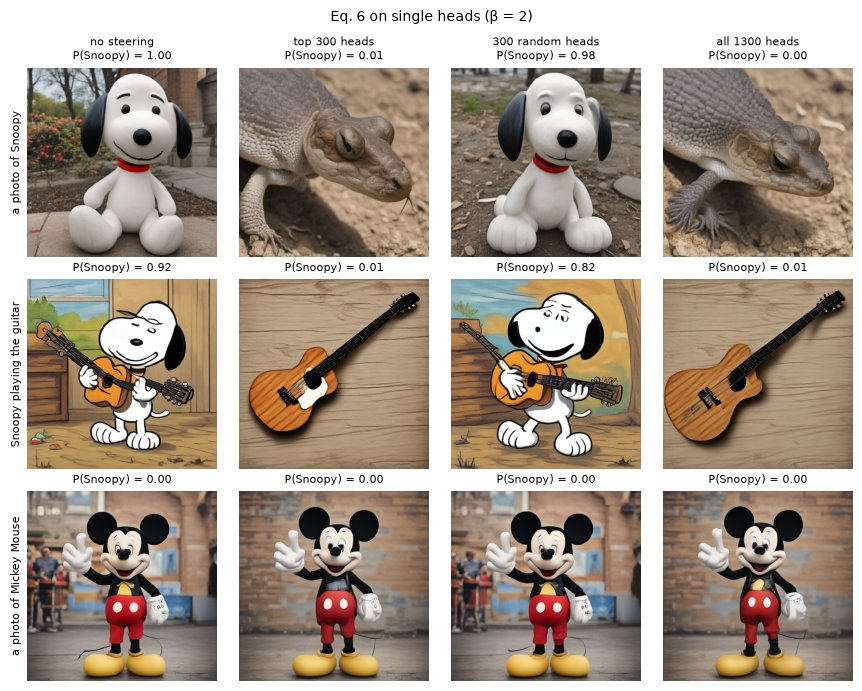

In [44]:
K = 300
rng = np.random.default_rng(0)
RANDOM_HEADS = [RANKED[i] for i in rng.choice(len(RANKED), K, replace=False)]
HEAD_SETTINGS = {"no steering": None, f"top {K} heads": RANKED[:K], f"{K} random heads": RANDOM_HEADS,
                 f"all {len(RANKED)} heads": RANKED}
HEAD_DEMO = ["a photo of Snoopy", "Snoopy playing the guitar", "a photo of Mickey Mouse"]
imgs = sweep(HEAD_DEMO, lambda hs: None if hs is None else casteer_heads(hs, B_HEADS), list(HEAD_SETTINGS.values()))
show_grid(imgs, len(HEAD_SETTINGS), judge_titles(imgs), row_labels=HEAD_DEMO, col_labels=list(HEAD_SETTINGS),
          suptitle="Eq. 6 on single heads (β = 2)")

The top 300 heads, less than a quarter of all heads, remove Snoopy almost as well as all 1300.
Editing 300 random heads changes nothing. Snoopy therefore depends on a subset of heads, rather than all equally.
How small is this subset, and which blocks contain it? Test this in task 3.3.

### Tasks §3

**3.1 · Which layers matter?** Erase with `casteer(B_ERASE, layers=...)` for `["down_blocks"]`, `["mid_block"]`,
`["up_blocks"]` and `["up_blocks.0"]`. Fill the six `TEMPLATES` with Snoopy and measure mean $P(\text{Snoopy})$ with
`p_label`. Is erasing in one part of the U-Net enough? Compare with the one-block result in §2.

In [46]:
# Task 3.1: your code


**3.2 · How many prompt pairs, and does clipping matter?** Estimate the erase direction from $N \in \{1, 5, 20, 50\}$
pairs: `direction(attn2_means(concept_prompts(TARGET, N)), attn2_means(concept_prompts(None, N)))` ($N = 1$ is a
single pair of prompts). For each $N$, erase with β = 2, once with `clip=True` and once with `clip=False`, and
measure:

* the mean $P(\text{Snoopy})$ on the six Snoopy `TEMPLATES`;
* the mean `similarity` of the `UNRELATED` images to their unsteered versions.

Plot both against $N$, one line per clipping mode. How many pairs are enough? How does clipping help? On which images
can you see its effect?

In [ ]:
# Task 3.2: your code


**3.3 · How many heads respond to Snoopy?** Erase with the top-$k$ heads and with $k$ random heads (`casteer_heads`),
for $k \in \{10, 30, 100, 300, \text{all}\}$. Plot mean $P(\text{Snoopy})$ on the six Snoopy `TEMPLATES` against $k$,
with one line for each selection method. Count the top-30 heads per block (`short(name)`). Are they spread across
the U-Net or concentrated in a few blocks? Does this match the block responses in task 2.1?

In [ ]:
# Task 3.3: your code


## 4. Sparse autoencoder features: is there one "Snoopy feature"?

A difference of means mixes everything that differs between the two prompt sets into one direction. 

A **sparse autoencoder** (SAE) represents an activation with many features. Only a few are active at a time, which
often makes them easier to interpret. [Surkov et al.](https://arxiv.org/abs/2410.22366)
([code](https://github.com/surkovv/sdxl-unbox), weights
[surokpro2/sdxl-saes](https://huggingface.co/surokpro2/sdxl-saes), MIT) trained SAEs on the residual updates of four
SDXL-Turbo blocks, including *up0.1* from §2.

We load the SAE and check the hook point. Then we inspect one prompt's top features and find those that distinguish
the Snoopy pairs. We switch them off, add them, and use them to edit part of an image.

The SAE encodes the residual update $\Delta h(p) \in \mathbb R^{1280}$ at each of the 16×16 positions of
`up_blocks.0.attentions.1`. This TopK SAE has 5120 features, $k = 10$ active per position.
$W_\text{enc}$ is the encoder matrix, $b_\text{pre}$ and $b_\text{lat}$ are biases, $z$ is the feature code,
and $d_f$ is a decoder direction:

$$z = \operatorname{ReLU}\big(\operatorname{TopK}_k(W_\text{enc}(\Delta h - b_\text{pre}) + b_\text{lat})\big), \qquad
\widehat{\Delta h} = b_\text{pre} + \sum_f z_f\, d_f, \quad \lVert d_f \rVert = 1 .$$

Feature $f$ has an activation map $z_f(p)$ over the image. Edits change only its term,
with a scale $s$ or an addition strength $a$:

* switch off / boost: $\Delta h(p) \leftarrow \Delta h(p) + (s - 1)\, z_f(p)\, d_f$ ($s = 0$ off, $s > 1$ boost);
* add everywhere: $\Delta h(p) \leftarrow \Delta h(p) + a\, m_f\, k\, d_f$, with $m_f$ the feature's mean activation.

We keep the SAE's reconstruction error, so $s = 1$, $a = 0$ changes nothing.

In this figure, $x$ is the update $\Delta h(p)$ of *up0.1* at one image position $p$
(1280 numbers), $f$ is its code $z(p)$ with 5120 features, and TopK keeps the $k = 10$ largest.

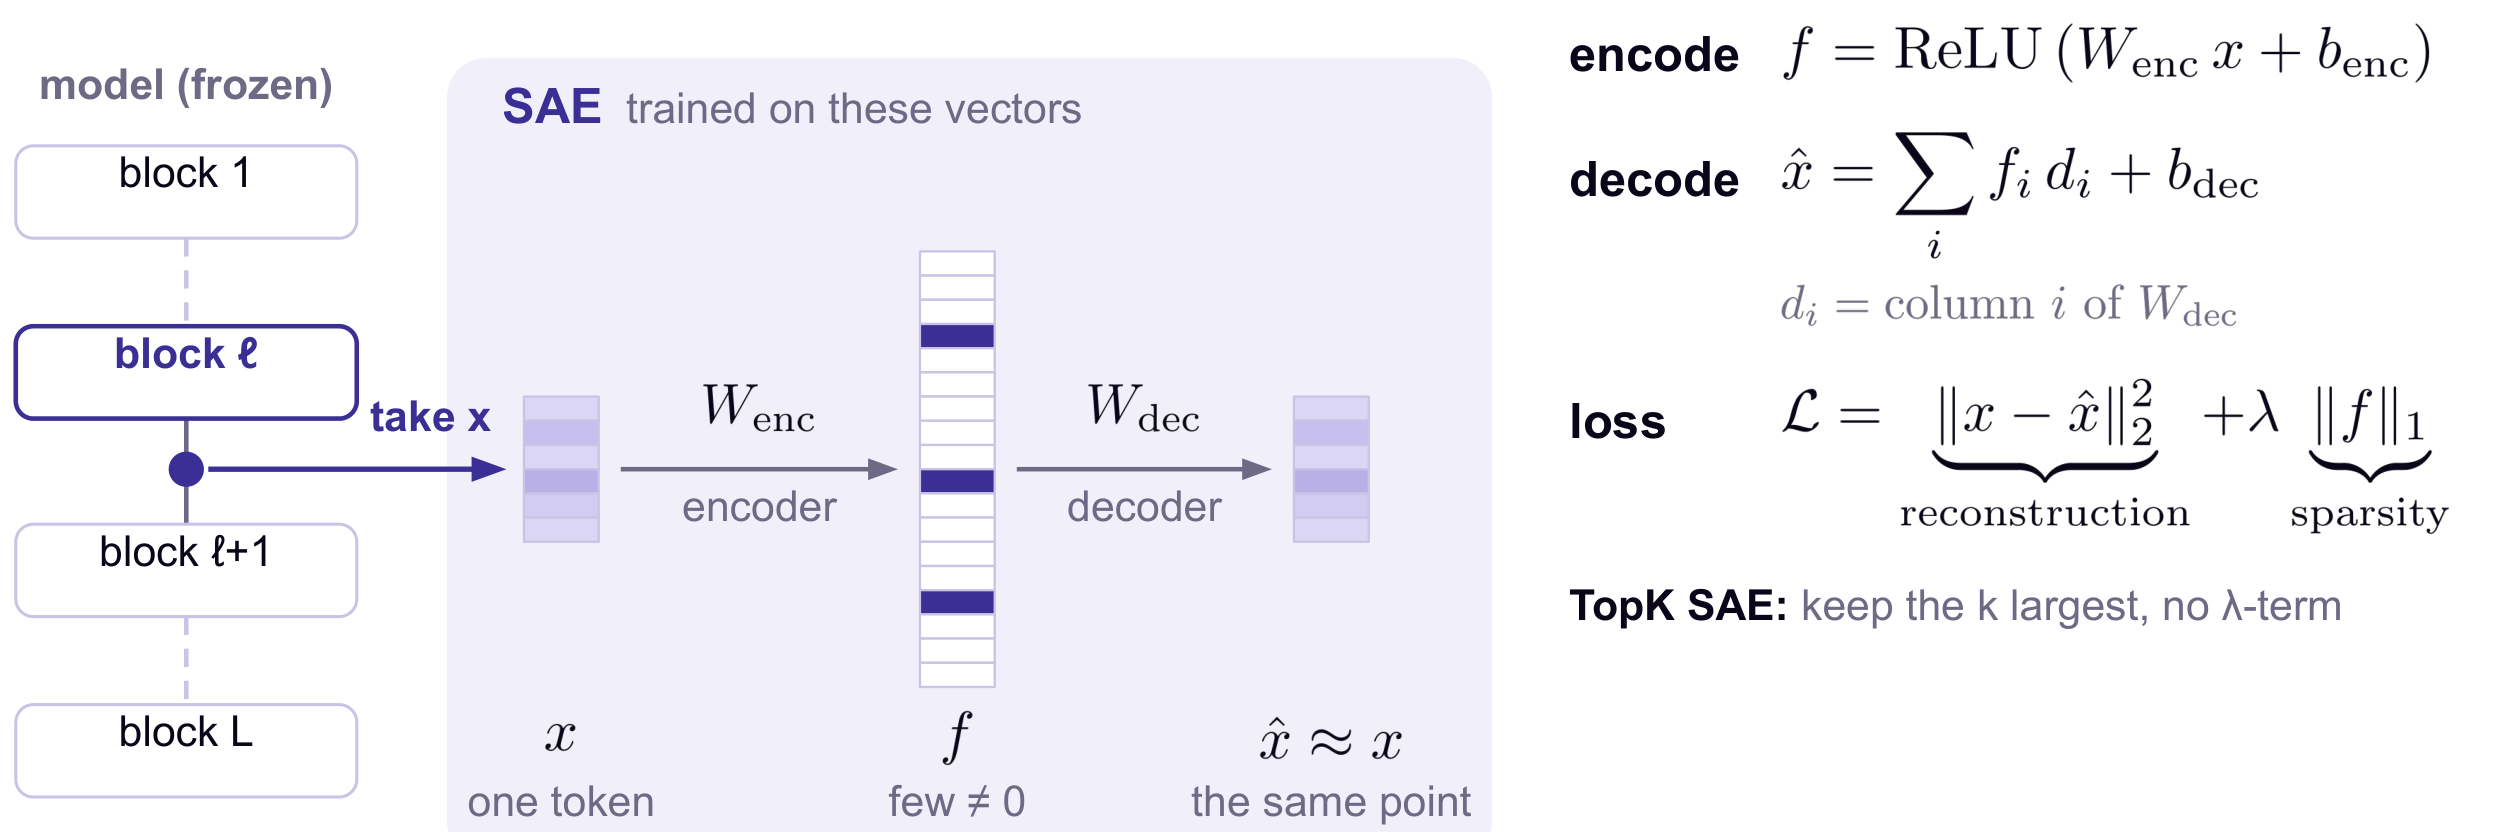

In [52]:
SAE_BLOCK = BLOCK     # "up_blocks.0.attentions.1"; SAEs also exist for "down_blocks.2.attentions.1",
                      # "mid_block.attentions.0" and "up_blocks.0.attentions.0"


class TopKSAE(nn.Module):
    """TopK sparse autoencoder with the parameter names of sdxl-unbox (SAE/sae.py), so their checkpoints load as is.

    encode: z = ReLU(TopK_k(W_enc (x - b_pre) + b_lat)); decode: x_hat = W_dec z + b_pre, unit-norm columns d_f = W_dec[:, f].
    """

    def __init__(self, d_model=1280, n_dirs=5120, k=10):
        super().__init__()
        self.k = k
        self.encoder = nn.Linear(d_model, n_dirs, bias=False)
        self.decoder = nn.Linear(n_dirs, d_model, bias=False)
        self.pre_bias = nn.Parameter(torch.zeros(d_model))
        self.latent_bias = nn.Parameter(torch.zeros(n_dirs))
        self.register_buffer("stats_last_nonzero", torch.zeros(n_dirs, dtype=torch.long))   # stored in their checkpoints

    def encode(self, x):
        """x [..., d_model] -> sparse codes z [..., n_dirs] (at most k non-zeros)."""
        pre = self.encoder(x - self.pre_bias) + self.latent_bias
        vals, idx = pre.topk(self.k, dim=-1)
        return torch.zeros_like(pre).scatter_(-1, idx, vals.relu())

    def decode(self, z):
        """z [..., n_dirs] -> reconstruction [..., d_model]."""
        return z @ self.decoder.weight.T + self.pre_bias


def load_sae(block, k=10, n_dirs=5120):
    """Download the pretrained sdxl-unbox SAE of `block` and load it strictly.

    Returns: (sae on DEVICE in float32, [n_dirs] mean activation of every feature).
    """
    folder = f"unet.{block}_k{k}_hidden{n_dirs}_auxk256_bs4096_lr0.0001"
    get = lambda f: hf_hub_download(SAE_REPO, f"{folder}/{f}")
    cfg = json.load(open(get("config.json")))
    sae = TopKSAE(cfg["d_model"], cfg["n_dirs_local"], cfg["k"])
    state = torch.load(get("state_dict.pth"), map_location="cpu", weights_only=True)["state_dict"]
    sae.load_state_dict(state, strict=True)
    mean = torch.load(get("mean.pt"), map_location="cpu", weights_only=True).float()
    return sae.to(DEVICE).eval(), mean

In [54]:
sae, feat_mean = load_sae(SAE_BLOCK)
print(f"SAE for {short(SAE_BLOCK)}: {sae.decoder.weight.shape[1]} features, k = {sae.k}")

PROMPT = "Snoopy playing the guitar in a park"
U, (img,) = block_update(PROMPT, SAE_BLOCK, decode=True)
upd = U[0].to(DEVICE)                                             # [16, 16, 1280]
z = sae.encode(upd)                                               # [16, 16, 5120]
err = ((upd - sae.decode(z)) ** 2).sum() / ((upd - upd.mean((0, 1))) ** 2).sum()
print(f"active features per position {(z > 0).sum(-1).float().mean():.1f}, explained variance {1 - err:.2f}")

SAE for up0.1: 5120 features, k = 10
active features per position 10.0, explained variance 0.64


**One position, step by step.** The plots show a position on Snoopy's head, its code $z(p)$ over all 5120 features
(only 10 are non-zero), and its strongest feature's map across the image, as in the figure above.

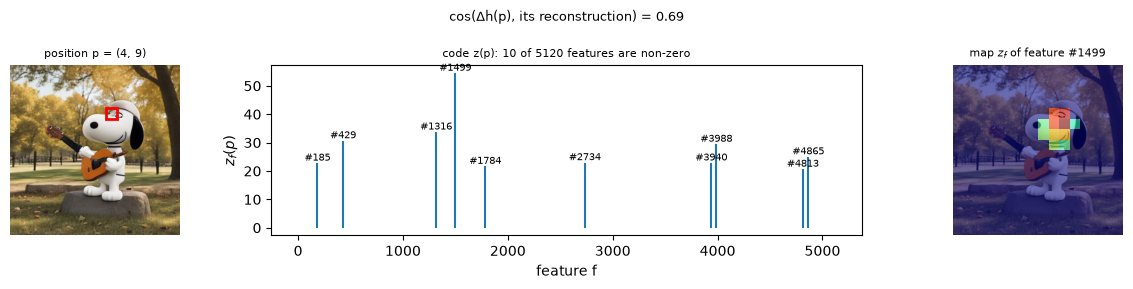

In [56]:
i, j = 4, 9                                                        # a position on Snoopy's head (16×16 grid)
zp = z[i, j].cpu()
active = zp.nonzero().flatten().tolist()
f0 = int(zp.argmax())
cell = img.width / z.shape[1]
fig, axes = plt.subplots(1, 3, figsize=(12, 2.9), gridspec_kw={"width_ratios": [1, 2.6, 1]})
axes[0].imshow(img); axes[0].add_patch(plt.Rectangle((j * cell, i * cell), cell, cell, fill=False, ec="red", lw=2))
axes[0].set_title(f"position p = ({i}, {j})", fontsize=8)
axes[1].stem(range(len(zp)), zp.numpy(), markerfmt=" ", basefmt=" ")
for f in active:
    axes[1].text(f, float(zp[f]), f"#{f}", fontsize=7, ha="center", va="bottom")
axes[1].set_xlabel("feature f"); axes[1].set_ylabel("$z_f(p)$")
axes[1].set_title(f"code z(p): {len(active)} of {len(zp)} features are non-zero", fontsize=8)
axes[2].imshow(img); axes[2].imshow(z[..., f0].cpu().numpy(), cmap="jet", alpha=0.55, interpolation="nearest",
                                    extent=(0, img.width, img.height, 0))
axes[2].set_title(f"map $z_f$ of feature #{f0}", fontsize=8)
for ax in (axes[0], axes[2]):
    ax.axis("off")
rec = sae.decode(z[i, j])
fig.suptitle(f"cos(Δh(p), its reconstruction) = {float(F.cosine_similarity(rec, upd[i, j], dim=0)):.2f}", fontsize=9)
plt.tight_layout(); plt.show()

Explained variance helps check our hook point. A good SAE explains most of the variance of the correct tensor.
For the wrong tensor, such as the block output instead of its update, it would explain far less.

**Top features of one prompt** are those with the largest mean activation over the image. We plot their maps below.

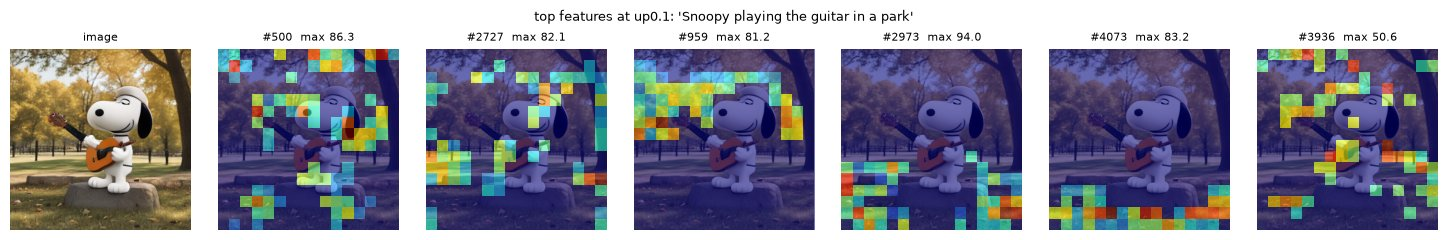

In [58]:
def show_feature_maps(image, codes, feats, title=""):
    """Overlay the activation maps codes[..., f] ([H, W, n_dirs] SAE codes) of the features `feats` on the image."""
    fig, axes = plt.subplots(1, len(feats) + 1, figsize=(2.1 * (len(feats) + 1), 2.4))
    axes[0].imshow(image); axes[0].set_title("image", fontsize=8)
    for ax, f in zip(axes[1:], feats):
        m = codes[..., f].cpu().numpy()
        ax.imshow(image)
        ax.imshow(m, cmap="jet", alpha=0.55, extent=(0, image.width, image.height, 0), interpolation="nearest",
                  vmin=0, vmax=max(m.max(), 1e-6))
        ax.set_title(f"#{f}  max {m.max():.1f}", fontsize=8)
    for ax in axes:
        ax.axis("off")
    fig.suptitle(title, fontsize=9); plt.tight_layout(); plt.show()


top = z.mean((0, 1)).topk(6).indices.tolist()
show_feature_maps(img, z, top, f"top features at {short(SAE_BLOCK)}: '{PROMPT}'")

**Snoopy features.** Rank features by their difference in mean activation on the §2 prompt pairs:
$\Delta\bar z_f = \bar z_f(p^+) - \bar z_f(p^-)$, averaging over positions and prompts on each side.
Inspect the top features on held-out prompts. Are they active only for Snoopy, or also for his neighbours?

Snoopy features: [2008, 1635, 4864, 312, 4328]  Δz: [5.21, 5.21, 3.69, 2.96, 2.46]


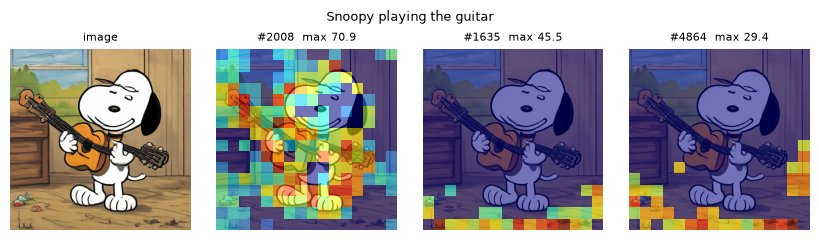

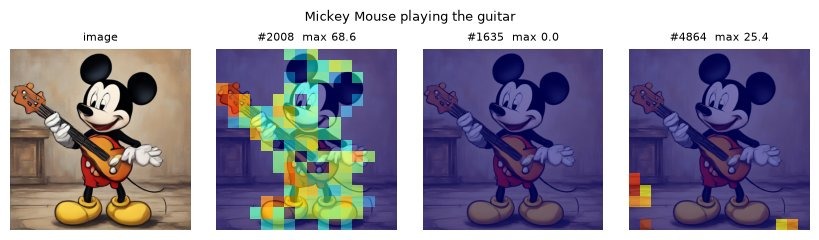

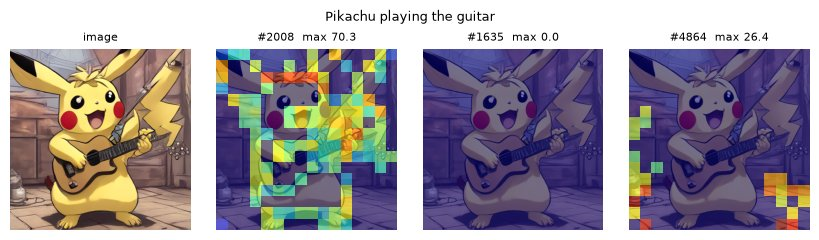

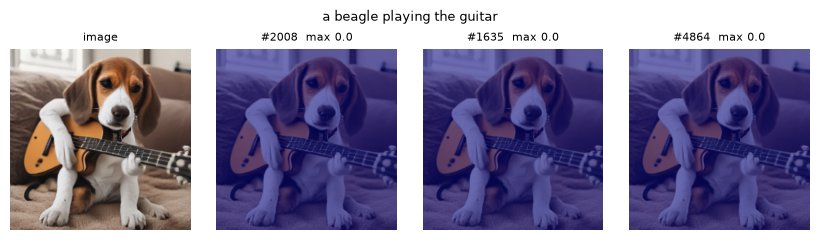

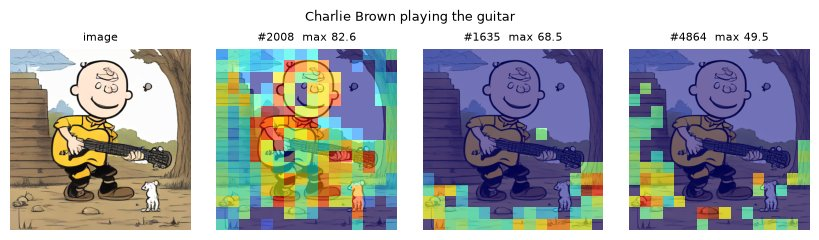

In [60]:
def mean_codes(prompts):
    """Mean SAE code over the image positions of each prompt: [n_prompts, n_dirs] on CPU."""
    U, _ = block_update(prompts, SAE_BLOCK)
    return torch.cat([sae.encode(U[i:i + 8].to(DEVICE)).mean((1, 2)).cpu() for i in range(0, len(U), 8)])


z_plain = mean_codes(concept_prompts(None, N_PAIRS)).mean(0)          # mean code of the plain class prompts
dz = mean_codes(concept_prompts(TARGET, N_PAIRS)).mean(0) - z_plain
SNOOPY_FEATS = dz.topk(5).indices.tolist()
print("Snoopy features:", SNOOPY_FEATS, " Δz:", [round(float(dz[f]), 2) for f in SNOOPY_FEATS])

for p in [TEMPLATES[1].format(c) for c in [TARGET] + NEIGHBOURS]:
    U, (im,) = block_update(p, SAE_BLOCK, decode=True)
    show_feature_maps(im, sae.encode(U[0].to(DEVICE)), SNOOPY_FEATS[:3], p)

**Switch the Snoopy features off** ($s = 0$, while $s = -2$ reverses their contribution).
Then **add one** where it was inactive ($a > 0$ on prompts without Snoopy).

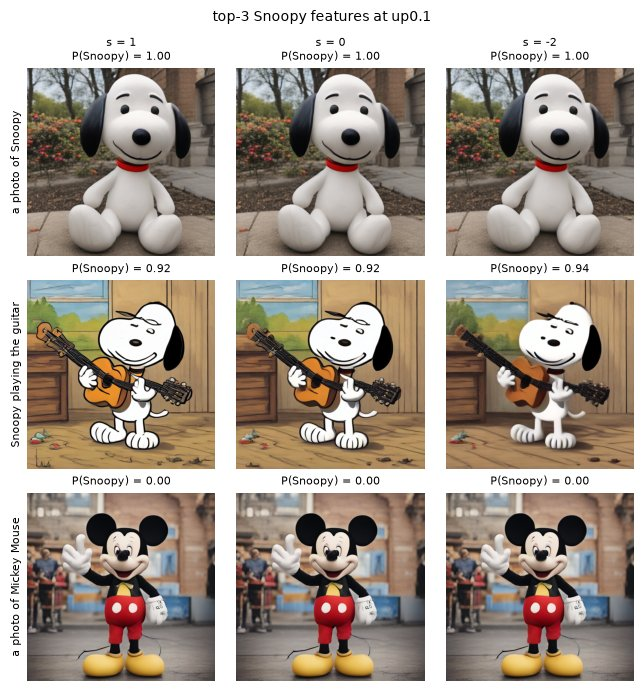

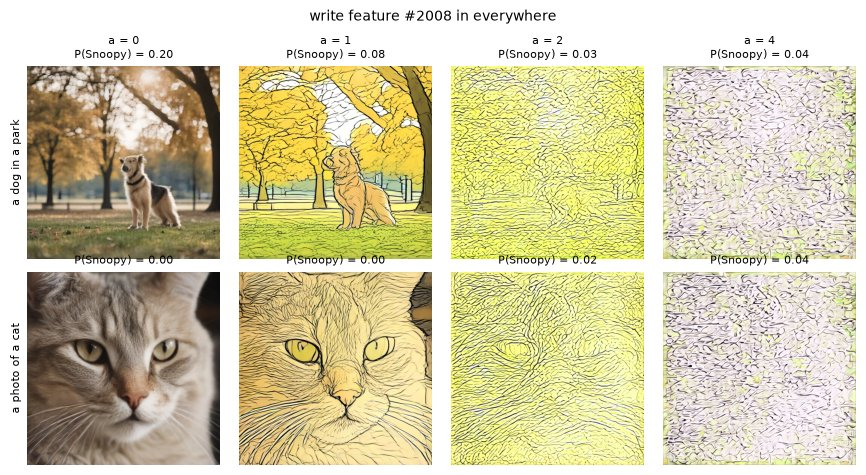

In [62]:
def sae_edit(features, scale=1.0, add=0.0, mask=None):
    """Hooks for `generate` that edit SAE features in the residual update of SAE_BLOCK.

    At every position p: Δh(p) += sum_f [(scale - 1) * z_f(p) + add * m_f * k] * d_f.
    scale = 0 switches the features off where they fire, > 1 boosts, < 0 pushes against them;
    add > 0 writes them in everywhere; mask: optional [H, W] 0/1 tensor, edit only these positions (a brush).
    """
    f = torch.tensor(features, device=DEVICE)
    D = sae.decoder.weight[:, f]                                   # [C, m]
    const = add * feat_mean[f.cpu()].to(DEVICE) * sae.k            # [m]
    w = 1.0 if mask is None else mask.to(DEVICE, torch.float32)[None, :, :, None]   # [1, H, W, 1]

    def edit(x_in, x_out):
        upd = (x_out - x_in).float().permute(0, 2, 3, 1)           # [b, H, W, C]
        coef = ((scale - 1) * sae.encode(upd)[..., f] + const) * w  # [b, H, W, m]
        return x_out + (coef @ D.T).permute(0, 3, 1, 2).to(x_out.dtype)

    return {SAE_BLOCK: edit}


SCALES = [1, 0, -2]
OFF_DEMO = ["a photo of Snoopy", "Snoopy playing the guitar", "a photo of Mickey Mouse"]
imgs = sweep(OFF_DEMO, lambda s: sae_edit(SNOOPY_FEATS[:3], scale=s), SCALES)
show_grid(imgs, len(SCALES), judge_titles(imgs), row_labels=OFF_DEMO, col_labels=[f"s = {s}" for s in SCALES],
          suptitle=f"top-3 Snoopy features at {short(SAE_BLOCK)}")

ADDS = [0, 1, 2, 4]
IN_DEMO = ["a dog in a park", "a photo of a cat"]
imgs = sweep(IN_DEMO, lambda a: sae_edit(SNOOPY_FEATS[:1], add=a), ADDS)
show_grid(imgs, len(ADDS), judge_titles(imgs), row_labels=IN_DEMO, col_labels=[f"a = {a}" for a in ADDS],
          suptitle=f"write feature #{SNOOPY_FEATS[0]} in everywhere")

**What is this feature?** In the second grid, the top Snoopy feature does not draw Snoopy. At a = 1, it already turns
the dog and cat into comics with black outlines, flat colours and yellowish paper. The strongest "Snoopy" features
at *up0.1* describe **how Snoopy is drawn**, the Peanuts line art, rather than **who he is**.

**A feature is a brush.** SAE edits act at each position separately. A mask lets us add a feature only to chosen
positions on the block's 16$\times$16 grid: the left half, a centre box, or everywhere.

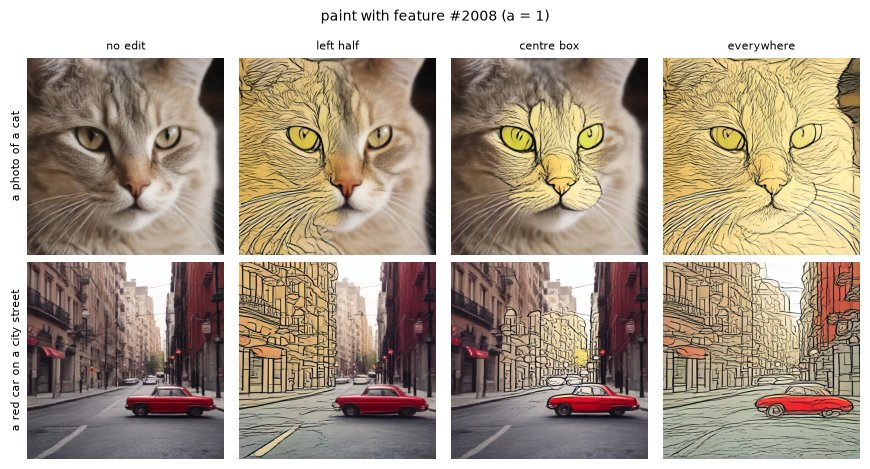

In [64]:
H = W = 16                                       # the grid of up0.1 at 512 px
left = torch.zeros(H, W); left[:, :W // 2] = 1
box = torch.zeros(H, W); box[4:12, 4:12] = 1
MASKS = {"no edit": None, "left half": left, "centre box": box, "everywhere": torch.ones(H, W)}
BRUSH_DEMO = ["a photo of a cat", "a red car on a city street"]
imgs = [generate(p, hooks=None if m is None else sae_edit(SNOOPY_FEATS[:1], add=1, mask=m))[0]
        for p in BRUSH_DEMO for m in MASKS.values()]
show_grid(imgs, len(MASKS), row_labels=BRUSH_DEMO, col_labels=list(MASKS),
          suptitle=f"paint with feature #{SNOOPY_FEATS[0]} (a = 1)")

**One feature, one style.** If the Snoopy feature represents a drawing style, other styles should have features too.
As before, choose the largest $\Delta\bar z_f$ between `"a {style} of a {cls}"` and `"{cls}"`.
Add each feature to a photo (a = 1), everywhere or only in the left half. We change one direction in 1280 dimensions,
without changing the prompt or training.

{'watercolor painting': 2445, 'pencil sketch': 2863, 'pixel art': 1186, 'mosaic': 870}


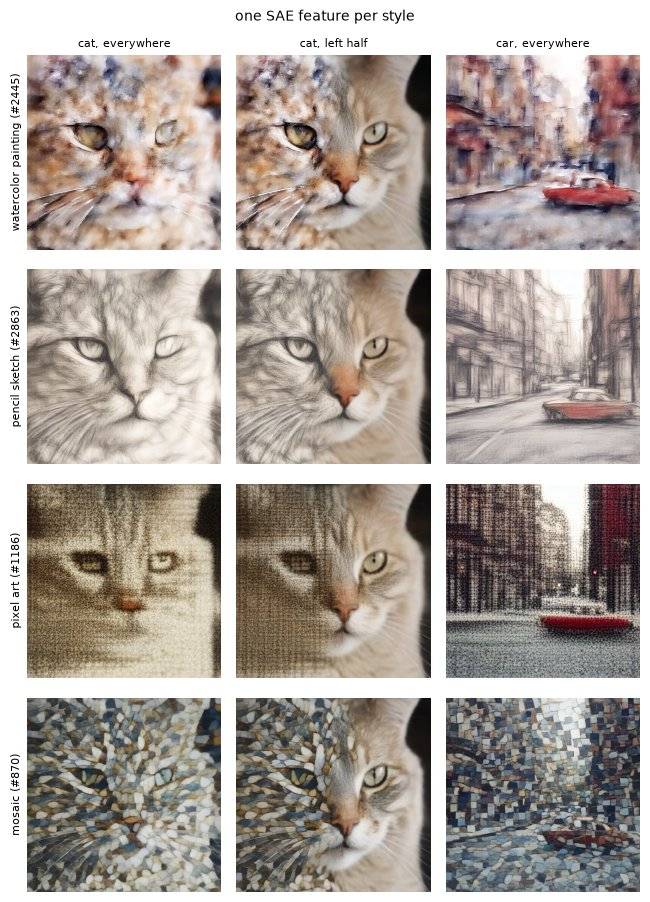

In [66]:
STYLES = ["watercolor painting", "pencil sketch", "pixel art", "mosaic"]
STYLE_FEATS = {s: int((mean_codes(concept_prompts(s, N_PAIRS, "a {concept} of a {cls}")).mean(0) - z_plain).argmax())
               for s in STYLES}
print(STYLE_FEATS)

STYLE_DEMO = [("a photo of a cat", None), ("a photo of a cat", left), ("a red car on a city street", None)]
imgs = [generate(p, hooks=sae_edit([f], add=1, mask=m))[0] for f in STYLE_FEATS.values() for p, m in STYLE_DEMO]
show_grid(imgs, len(STYLE_DEMO), row_labels=[f"{s} (#{f})" for s, f in STYLE_FEATS.items()],
          col_labels=["cat, everywhere", "cat, left half", "car, everywhere"], suptitle="one SAE feature per style")

Each style corresponds to one feature: four directions produce four different looks. With a mask, the style stays
in one half and leaves the other half's photo unchanged. Some features work better than others:
the pixel-art feature produces a grid texture rather than real pixels.

### Tasks §4

**4.1 · Another block.** Set `SAE_BLOCK = "down_blocks.2.attentions.1"` and reload the SAE.
Repeat the Snoopy-feature search and plot the maps. Compare object layout, texture and colour with the previous block.
Which block gives a feature active for Snoopy but not Mickey?

In [68]:
# Task 4.1: your code


**4.2 · How many features?** Switch off the top-$m$ Snoopy features, $m \in \{1, 3, 10\}$ (`dz.topk(m).indices`), with
`sae_edit(...)`. Measure $P(\text{Snoopy})$ on the six Snoopy `TEMPLATES` using `p_label`, and `similarity` between
steered and unsteered `NEIGHBOURS` images. Compare with direction $d$ from §2 at the same block. Is one feature "the"
Snoopy feature?

In [70]:
# Task 4.2: your code


**4.3 · Draw a feature from nothing.** Use the top Snoopy feature (`SNOOPY_FEATS[0]`) as $f$. Generate the empty prompt
`""` with `sae_edit([f], add=a)` for $a \in \{0, 1, 2, 4\}$, the sdxl-unbox trick. Inspect what it draws on its own.
Repeat for one of the top features of `PROMPT`.

In [72]:
# Task 4.3: your code


**4.4 · Your own brush.** Choose a style or material, such as `"made of LEGO"`, `"on fire"` or `"in the snow"`.
Find its feature using the $\Delta\bar z_f$ ranking. Add it within your own mask, such as a circle or the top half.
Repeat with an object (`"a hat"`, `"a tree"`). Which work as a brush at *up0.1*, and why?

In [74]:
# Task 4.4: your code


## 5. Research task (choose one)

Choose **one** question and write up a small study:

1. **hypothesis:** state what you expect and what result would prove you wrong.
2. **experiment:** design the smallest test that answers the question.
3. **one figure** that shows the answer.
4. **conclusion** in 3–5 sentences, including what you would try next.

Keep it small (a few prompts, 1–3 seeds), but back every claim with a number or an image. Use the helpers below:
`clip_prob` scores images against your own label set (the judge of §1 only knows its fixed labels), and
`pair_prompts` builds prompt pairs from any template.

### Option A · Which blocks control Snoopy?

Task 2.1 found one block that responds much more than the others. Task 3.3 found most Snoopy heads in the same place.
Does that location control whether Snoopy appears? A location $L$ (a block, or a set of blocks) should pass two tests:

* **necessary:** erase Snoopy **only in $L$** (`casteer(B_ERASE, layers=[...])`): does he disappear? Then erase
  everywhere **except** $L$: does he survive?
* **sufficient:** add Snoopy **only in $L$** (`casteer_add(D_ADD, alpha, layers=[...])`) to `"a dog in a park"` or
  `"a photo of a cat"`: does he appear?

Test every block (`BLOCKS` are valid `layers` prefixes) and plot the results in one figure, such as a scatter plot with
$x$ = $P(\text{Snoopy})$ after erasing only here, $y$ = $P(\text{Snoopy})$ after adding only here. Is there a block that is
both necessary and sufficient? Does erasing in that block preserve the neighbours (Mickey, Charlie Brown)?

### Option B · Which concepts can be steered?

Everything so far was about one character. Does the same recipe work for other **kinds** of concepts? Take at least
four: a character (e.g. Pikachu), an object (a guitar), a style (Van Gogh), a colour (red). For each:

1. Build pairs with `pair_prompts` (e.g. `"{cls} with a guitar"` against `"{cls}"`, or `"a red {cls}"` against
   `"a {cls}"`) and compute the CASteer erase direction.
2. Write 3 test prompts containing the concept. Choose a `clip_prob` label set that distinguishes it (e.g.
   `["a painting by Van Gogh", "a photo", "a painting"]`).
3. Measure the concept probability before and after erasing (β = 2), and `similarity` on `UNRELATED`.

Plot each concept's probability before and after erasing in one figure. Which kinds are easy to erase, which are not,
and why could that be? Look at the images: what does the model draw instead?

In [76]:
def clip_prob(images, texts):
    """CLIP probability of texts[0] among `texts` for each image: [n] numpy array. Use your own label set."""
    emb = clip_texts([f"a picture of {t}" for t in texts])
    return (100.0 * clip_images(images) @ emb.T).softmax(-1)[:, 0].numpy()


def pair_prompts(template, n=N_PAIRS_CA, concept=TARGET):
    """Prompts from the first n ImageNet classes, e.g. pair_prompts("a red {cls}") or pair_prompts("{cls} with {concept}")."""
    return [template.format(cls=c, concept=concept) for c in IMAGENET[:n]]


print(pair_prompts("a red {cls}", 3), pair_prompts("{cls}", 3))
imgs = generate(["a photo of Snoopy", "a red car on a city street"])
print("P(Snoopy among Snoopy / a dog / a cat):", clip_prob(imgs, ["Snoopy", "a dog", "a cat"]).round(2))

['a red tench', 'a red goldfish', 'a red great white shark'] ['tench', 'goldfish', 'great white shark']


P(Snoopy among Snoopy / a dog / a cat): [1.  0.6]


In [ ]:
# Task 5 (option A): your code


In [ ]:
# Task 5 (option B): your code
